# 13 · IA centrada en los datos: mejores datos, mejores modelos

Este es un módulo de Neural Networks 1002. Supone el [módulo 03 de Neural Networks 1001](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) (entrenar bien redes profundas: pérdidas, regularización, sobreajuste, cómo una red puede memorizar etiquetas con ruido) y el [módulo 12](https://neural-networks.academy.forwardforecasting.eu/es/12-proyecto-final-caso-real/) (el proyecto final, donde la calidad de los datos decide si se puede confiar en el modelo).

La mayoría de los cursos, incluidos los diez primeros módulos de esta secuencia, tratan el **conjunto de datos como fijo** y preguntan cómo mejorar el **modelo**. La IA centrada en los datos da la vuelta a esto: se mantienen fijos el modelo y la receta de entrenamiento, y el esfuerzo se dedica a los datos (etiquetas, cobertura, duplicados, particiones, monitorización). Andrew Ng popularizó el nombre en 2021, defendiendo que en muchos problemas prácticos los datos son donde están las mejoras mayores y más baratas. Eso es una afirmación, no una ley, así que en este cuaderno la **ponemos a prueba**: cada afirmación de abajo está respaldada por un número que medimos, y donde la vía centrada en los datos *no* gana lo decimos.

En este cuaderno construirás y medirás, en la CPU de un portátil y con semillas fijas:

1. el **coste del ruido en las etiquetas** (exactitud frente a tasa de ruido, para errores aleatorios y dependientes de la clase), y cómo las etiquetas ruidosas del conjunto de prueba distorsionan la propia medición;
2. **encontrar etiquetas erróneas** con el **aprendizaje confiado** (confident learning), con una regla **basada en la pérdida** y con el **desacuerdo de un conjunto de modelos**, comparados con la biblioteca `cleanlab`;
3. un **concurso justo**: un modelo fijo con mejores datos frente a la misma tarea con un modelo mayor, un modelo ajustado u otra familia de modelos (centrado en el modelo), con tres niveles de ruido incluido el ruido cero;
4. la **calidad de la anotación**: kappa de Cohen, clases ambiguas y lo que aportan unas mejores guías de etiquetado;
5. **fugas de datos y duplicados**: detección de casi duplicados, la puntuación de prueba inflada que provocan, particiones por grupos y una variable que filtra la respuesta;
6. **curvas de aprendizaje** con bandas de confianza y una extrapolación con ley de potencias para decidir entre recoger datos y cambiar el modelo;
7. la **valoración de datos**: valores de dejar uno fuera (leave-one-out) y de Shapley por Monte Carlo en un conjunto de entrenamiento pequeño;
8. el **aprendizaje activo**: muestreo por incertidumbre, margen, diversidad e híbrido frente al aleatorio, con variación de semillas y ahorro de presupuesto de etiquetado;
9. el **aumento de datos y los datos sintéticos**, incluido un juguete del **colapso de modelos** al entrenar con datos generados;
10. la **supervisión débil**: funciones de etiquetado y un pequeño modelo de etiquetas al estilo Snorkel;
11. la **validación y monitorización de datos en producción**: comprobaciones de esquema, el índice de estabilidad de la población (PSI, population stability index) y la prueba de Kolmogorov-Smirnov (KS) sobre un ejemplo resuelto de deriva;
12. la **documentación y el versionado**: una hoja de datos (datasheet) y un hash del contenido, y una lista de comprobación.

**Contenidos**

1. La tesis y nuestro montaje
2. Lo que cuesta el ruido en las etiquetas
3. Encontrar etiquetas erróneas
4. Centrado en el modelo frente a centrado en los datos en una misma tarea
5. Calidad de la anotación: acuerdo, ambigüedad, guías
6. Fugas, duplicados y particiones por grupos
7. Curvas de aprendizaje: ¿más datos o un modelo mejor?
8. El valor de cada dato
9. Aprendizaje activo
10. Aumento de datos, datos sintéticos y colapso de modelos
11. Supervisión débil
12. Validación y monitorización en producción
13. Documentación y versionado
14. Una lista de comprobación, ideas clave, ejercicios, referencias

| Se apoya en | Qué reutilizamos |
|---|---|
| [03 Entrenar redes profundas (1001)](https://neural-networks.academy.forwardforecasting.eu/es/03-entrenar-bien-redes-profundas/) | entropía cruzada, regularización, sobreajuste, memorización de etiquetas con ruido |
| [12 Proyecto final (1001)](https://neural-networks.academy.forwardforecasting.eu/es/12-proyecto-final-caso-real/) | juzgar un modelo con datos realistas, el coste de unas malas etiquetas de inspección |
| [11 Incertidumbre, calibración y robustez (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/11-incertidumbre-calibracion-y-robustez/) | las probabilidades predichas como señal, ideas de predicción conforme y de cambio de distribución usadas aquí para monitorizar |
| [12 IA responsable (1002)](https://neural-networks-1002.academy.forwardforecasting.eu/es/12-ia-responsable/) | quién está representado en los datos, la documentación como herramienta de responsabilidad |

¿Eres nuevo en scikit-learn, pandas o en las pruebas estadísticas? La [sección de marcos de IA del curso Python 1001](https://python.academy.forwardforecasting.eu/es/11-frameworks-de-ia/) cubre las herramientas, y su [sección de series temporales](https://python.academy.forwardforecasting.eu/es/12-prevision-de-series-temporales/) cubre la evaluación con datos que se mueven en el tiempo.

**Datos y en qué se diferencian los juguetes de los sistemas reales.** Casi todo usa los dígitos manuscritos de 8 por 8 píxeles que incluye scikit-learn (1797 imágenes, el conjunto de prueba de "Optical Recognition of Handwritten Digits" del UCI de Alpaydin y Kaynak, licencia CC BY 4.0, [doi:10.24432/C50P49](https://doi.org/10.24432/C50P49)), así que no se descarga nada; unos pocos juguetes (colapso de modelos, deriva) se generan en el cuaderno. **Inyectamos** los errores (etiquetas cambiadas, duplicados, deriva) para conocer la verdad y poder puntuar cada método, algo que los proyectos reales nunca pueden hacer; los errores de etiquetas reales no son aleatorios, los conjuntos reales tienen millones de filas y el daño rara vez es tan limpio. Los métodos y las mediciones se trasladan, los números exactos no. El cuaderno usa `cleanlab` (biblioteca de código abierto, licencia Apache 2.0, [github.com/cleanlab/cleanlab](https://github.com/cleanlab/cleanlab)) para una comprobación cruzada y funciona igualmente si no está instalada. Tiempo de ejecución: unos 3 minutos con cuatro núcleos de CPU rápidos (varias secciones ejecutan sus semillas en paralelo; el número de procesos sigue a `os.cpu_count()`), unos 5 minutos limitado a 2 vCPU (medido de nuevo en un entorno limpio: 5,5 minutos); una CPU de Colab más lenta puede necesitar algo más. En Colab, `pip install cleanlab` es opcional: sin ella simplemente se omite la línea de comprobación con la biblioteca.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/fborbon/academy/blob/main/neural-networks-1002/es/13_ia_centrada_en_datos.ipynb)

**¿Lo ejecutas en Google Colab?** Elige *Entorno de ejecución > Ejecutar todo*. La primera celda de código instala solo lo que falta (no hace falta reiniciar la sesión). **Tiempo medido** en un entorno limpio de 2 CPU como el de Colab: unos 5 minutos, con un pico de memoria de menos de 1 GB (las descargas de modelos y datos se hicieron con una conexión rápida). Una CPU gratuita de Colab suele ser más lenta que la máquina usada para medir, así que cuenta con más tiempo; los tiempos impresos en las salidas guardadas vienen de una máquina con varios núcleos.

In [ ]:
# Preparación: funciona en local y en Google Colab. Instala solo los paquetes que faltan.
import importlib.util, os, subprocess, sys

IN_COLAB = 'google.colab' in sys.modules
_NEEDED = {
    'cleanlab': 'cleanlab',
    'matplotlib': 'matplotlib',
    'numpy': 'numpy',
    'pandas': 'pandas',
    'scipy': 'scipy',
    'sklearn': 'scikit-learn',
}  # import name -> pip requirement
_missing = [req for mod, req in _NEEDED.items() if importlib.util.find_spec(mod) is None]
if _missing:
    print('Instalando:', ', '.join(_missing))
    _r = subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', *_missing], capture_output=True, text=True)
    if _r.returncode:
        print('ADVERTENCIA: la instalación con pip falló; se continúa. Detalle:\n' + _r.stderr[-400:])
print(f"Entorno: Python {sys.version.split()[0]} | {'Google Colab' if IN_COLAB else 'local'} | CPUs: {os.cpu_count()}")

In [1]:
import warnings
warnings.filterwarnings("ignore")
import os, time, math, json, hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats, ndimage
from scipy.optimize import curve_fit
from scipy.sparse.csgraph import connected_components
from scipy.sparse import coo_matrix
from joblib import Parallel, delayed
from threadpoolctl import threadpool_limits
from sklearn.datasets import load_digits
from sklearn.model_selection import (train_test_split, StratifiedKFold, GroupShuffleSplit, cross_val_score)
from sklearn.neural_network import MLPClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.mixture import GaussianMixture
from sklearn.metrics import accuracy_score, cohen_kappa_score, roc_auc_score
from sklearn.metrics.pairwise import pairwise_distances

try:
    from cleanlab.filter import find_label_issues
    HAVE_CLEANLAB = True
except Exception:
    HAVE_CLEANLAB = False

plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3
T_START = time.time()
K = 10

digits = load_digits()
X_ALL = (digits.data / 16.0).astype(float)      # valores de píxel escalados a [0, 1]
Y_ALL = digits.target
# una partición fija usada por casi todas las secciones: un conjunto de 1200 imágenes y un conjunto de prueba de 597 que nunca se toca
X_pool, X_test, y_pool, y_test = train_test_split(X_ALL, Y_ALL, test_size=597, stratify=Y_ALL, random_state=0)
Xtr, ytr = X_pool[:1000], y_pool[:1000]          # el conjunto de entrenamiento de las secciones 2 a 4
print("conjunto:", X_pool.shape, "prueba:", X_test.shape, "cleanlab instalada:", HAVE_CLEANLAB)

def _call(fn, a):
    warnings.filterwarnings("ignore")
    with threadpool_limits(1):
        return fn(a)
N_JOBS = int(os.environ.get("NN_THREADS") or min(4, os.cpu_count() or 1))     # 2 on a Colab CPU runtime
def pmap(fn, items, n_jobs=N_JOBS):
    # ejecuta semillas independientes en paralelo, un hilo cada una (los resultados no dependen de n_jobs)
    return Parallel(n_jobs=n_jobs)(delayed(_call)(fn, a) for a in items)

def mlp(seed=0, hidden=(64,), alpha=1e-4, iters=150):
    return MLPClassifier(hidden, alpha=alpha, max_iter=iters, learning_rate_init=3e-3, random_state=seed)
def logreg():
    return LogisticRegression(max_iter=300)

# dos tipos de errores de etiqueta, aplicados a un vector de etiquetas limpio
PAIR = {0: 6, 1: 7, 2: 7, 3: 8, 4: 9, 5: 9, 6: 0, 7: 1, 8: 3, 9: 4}     # pareja parecida de cada clase
def flip_sym(y, rate, seed):
    # ruido simétrico: una fracción aleatoria `rate` de las etiquetas se sustituye por otra clase al azar
    r = np.random.default_rng(seed); n = int(round(rate * len(y)))
    idx = r.choice(len(y), n, replace=False); y2 = y.copy()
    y2[idx] = (y[idx] + r.integers(1, K, n)) % K
    return y2
def flip_pair(y, rate, seed):
    # ruido dependiente de la clase: cada etiqueta pasa a su pareja parecida con probabilidad `rate`
    r = np.random.default_rng(seed); y2 = y.copy(); m = r.random(len(y)) < rate
    y2[m] = np.array([PAIR[v] for v in y[m]], dtype=y.dtype)
    return y2
def noisy(y, kind, rate, seed):
    return flip_sym(y, rate, seed) if kind == "symmetric" else flip_pair(y, rate, seed)

conjunto: (1200, 64) prueba: (597, 64) cleanlab instalada: True


## 1. La tesis y nuestro montaje

La visión **centrada en el modelo**: los datos vienen dados; se mejoran los resultados cambiando la arquitectura, el tamaño, el optimizador o los hiperparámetros (los ajustes que se eligen antes de entrenar, como la anchura o la fuerza de la regularización). La visión **centrada en los datos**: el modelo es suficientemente bueno y está fijo; se mejoran los resultados mejorando los datos de forma sistemática: corrigiendo etiquetas erróneas, eliminando duplicados, cubriendo los casos raros, escribiendo guías de etiquetado claras, partiendo los datos con honestidad y vigilándolos en producción. No son enemigas; la pregunta es **dónde rinde más la siguiente unidad de esfuerzo**.

La evidencia para tomarse en serio los datos es en parte medida y en parte experiencia. Northcutt, Athalye y Mueller (2021) encontraron errores de etiqueta en los **conjuntos de prueba** de diez de los bancos de pruebas más usados, un 3,4 % de media erróneo, suficiente para cambiar qué modelo parece el mejor. Sambasivan et al. (2021) entrevistaron a profesionales de ámbitos de alto riesgo y describieron las **cascadas de datos** (data cascades): problemas de datos que empiezan pronto, son invisibles y se acumulan aguas abajo, con un 92 % de los equipos que informaron de al menos una. Esos son hallazgos sobre la práctica. Aquí hacemos algo más pequeño y más comprobable: repetir los mismos experimentos en una tarea pequeña y ver qué palancas mueven el número.

En todo el cuaderno, "exactitud" significa exactitud en el conjunto de prueba limpio de 597 imágenes de dígitos. Su error típico binomial es de unos $\sqrt{0.95 \cdot 0.05 / 597} \approx 0.9$ puntos porcentuales, así que **las diferencias menores de un punto entre ejecuciones sueltas son ruido**; repetimos las ejecuciones con varias semillas (una *semilla* es el número que fija las elecciones aleatorias) y damos medias con sus dispersiones.

## 2. Lo que cuesta el ruido en las etiquetas

Tomamos las 1000 imágenes de entrenamiento y corrompemos una fracción $\rho$ (la letra griega rho, la **tasa de ruido**) de sus etiquetas, de dos maneras:

* **Ruido simétrico**: una etiqueta elegida se sustituye por una clase *distinta* al azar y uniforme. Es el caso más fácil de estudiar y el menos realista.
* **Ruido dependiente de la clase (por pares)**: una etiqueta se convierte en su pareja parecida (1 con 7, 3 con 8, 4 con 9, 5 con 9, 0 con 6, 2 con 7) con probabilidad $\rho$. Imita a una persona que confunde cosas parecidas, y es **más difícil**, porque los errores son sistemáticos y un modelo puede aprenderlos.

Entrenamos una red neuronal pequeña (un perceptrón multicapa con una capa oculta de 64 unidades) y una regresión logística con las etiquetas ruidosas y medimos la exactitud en el conjunto de prueba **limpio**. También medimos la exactitud frente a un conjunto de prueba corrompido de la misma manera, para mostrar un segundo coste del ruido: incluso un modelo perfecto parece peor cuando las etiquetas de *prueba* son erróneas.

    ruido  tasa  MLP prueba limpia  MLP prueba ruidosa  LogReg prueba limpia
symmetric   0.0           0.977           0.977              0.968
symmetric   0.1           0.938           0.844              0.950
symmetric   0.2           0.909           0.730              0.936
symmetric   0.3           0.882           0.618              0.920
symmetric   0.4           0.828           0.505              0.883
symmetric   0.5           0.733           0.377              0.846
     pair   0.0           0.977           0.977              0.968
     pair   0.1           0.928           0.837              0.950
     pair   0.2           0.873           0.719              0.913
     pair   0.3           0.798           0.616              0.851
     pair   0.4           0.655           0.524              0.711
     pair   0.5           0.492           0.495              0.479


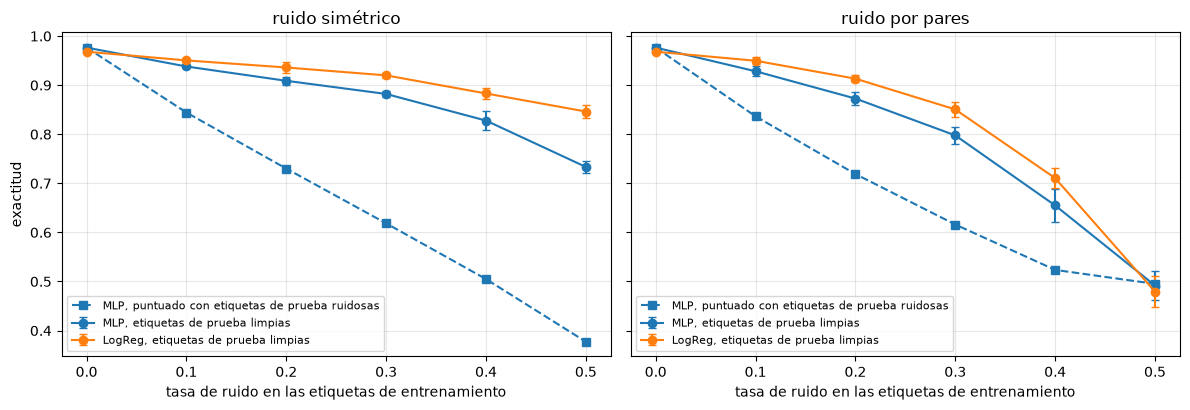

tiempo 6 s


In [2]:
rates = [0, 0.1, 0.2, 0.3, 0.4, 0.5]
seeds3 = [0, 1, 2, 3, 4]

def noise_task(args):
    kind, rate, s = args
    yn = noisy(ytr, kind, rate, 100 + s)
    yt_noisy = noisy(y_test, kind, rate, 200 + s)
    out = {}
    for name, m in [("MLP", mlp(s)), ("LogReg", logreg())]:
        p = m.fit(Xtr, yn).predict(X_test)
        out[name] = (accuracy_score(y_test, p), accuracy_score(yt_noisy, p))
    return out

t0 = time.time()
jobs = [(k, r, s) for k in ["symmetric", "pair"] for r in rates for s in seeds3]
res = dict(zip(jobs, pmap(noise_task, jobs)))

fig, ax = plt.subplots(1, 2, figsize=(12, 4.2), sharey=True)
print(f"{'ruido':>9s} {'tasa':>5s} {'MLP prueba limpia':>18s} {'MLP prueba ruidosa':>19s} {'LogReg prueba limpia':>21s}")
for a, kind in zip(ax, ["symmetric", "pair"]):
    for name, c, ls in [("MLP", "C0", "-"), ("LogReg", "C1", "-")]:
        m = np.array([[np.mean([res[(kind, r, s)][name][0] for s in seeds3]),
                       np.std([res[(kind, r, s)][name][0] for s in seeds3])] for r in rates])
        a.errorbar(rates, m[:, 0], m[:, 1], color=c, ls=ls, marker="o", capsize=3, label=f"{name}, etiquetas de prueba limpias")
    mn = np.array([np.mean([res[(kind, r, s)]["MLP"][1] for s in seeds3]) for r in rates])
    a.plot(rates, mn, "C0--", marker="s", label="MLP, puntuado con etiquetas de prueba ruidosas")
    a.set_xlabel("tasa de ruido en las etiquetas de entrenamiento"); a.set_title(f"ruido {'simétrico' if kind == 'symmetric' else 'por pares'}"); a.legend(fontsize=8)
    for r in rates:
        mm = np.mean([res[(kind, r, s)]["MLP"][0] for s in seeds3]); mt = np.mean([res[(kind, r, s)]["MLP"][1] for s in seeds3])
        ml = np.mean([res[(kind, r, s)]["LogReg"][0] for s in seeds3])
        print(f"{kind:>9s} {r:5.1f} {mm:15.3f} {mt:15.3f} {ml:18.3f}")
ax[0].set_ylabel("exactitud")
plt.tight_layout(); plt.show()
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** La exactitud cae de forma constante con la tasa de ruido, y la *estructura* del ruido importa. Con ruido simétrico la red conserva 0,909 con un 20 % de ruido y 0,828 con un 40 % (desde 0,977 con etiquetas limpias), porque las etiquetas erróneas se reparten entre nueve clases y la clase correcta sigue ganando de media. Con ruido de pareja parecida las mismas tasas cuestan más, 0,873 con un 20 % y 0,655 con un 40 %, y con un 50 % el modelo queda en 0,49: la mitad de los 1 se etiquetan como 7 y nada en los datos dice cuál mitad. Dos observaciones más. Primero, el **modelo más simple es más robusto**: la regresión logística es peor que la red con etiquetas limpias (0,968 frente a 0,977) pero mejor desde un 10 % de ruido (0,936 frente a 0,909 con un 20 % de ruido simétrico, 0,913 frente a 0,873 con un 20 % de ruido por pares), porque la red tiene capacidad para memorizar etiquetas erróneas y la regresión logística no. Segundo, la línea discontinua muestra el **coste de las etiquetas de prueba ruidosas**: puntuadas contra un conjunto de prueba corrompido con la misma tasa, las mismas predicciones parecen mucho peores (0,730 en lugar de 0,909 con un 20 % de ruido simétrico, cerca de la exactitud limpia multiplicada por $1-\rho$). La diferencia entre dos modelos se encoge en un factor parecido y se vuelve más ruidosa, que es como los errores de etiqueta de un conjunto de prueba pueden reordenar una clasificación (Northcutt, Athalye y Mueller, 2021). Las barras de error del gráfico son una desviación típica sobre 5 semillas. En datos reales el ruido rara vez es uniforme y rara vez se conoce; esta sección solo fija una escala.

## 3. Encontrar etiquetas erróneas

Si las etiquetas erróneas cuestan exactitud, ¿podemos **encontrarlas**? Tres familias de métodos, todos basados en la misma idea: *un modelo que no ha visto un ejemplo (fuera de muestra) y discrepa con fuerza de su etiqueta es indicio de que la etiqueta está mal*. Para obtener predicciones fuera de muestra de cada ejemplo de entrenamiento usamos **validación cruzada de 5 pliegues**: dividimos el conjunto de entrenamiento en cinco partes, entrenamos con cuatro, predecimos la quinta y rotamos. Esto da un vector de probabilidades fuera de muestra $\hat p_i$ para cada ejemplo $i$ (un vector sobre las $K = 10$ clases).

1. **Aprendizaje confiado** (Northcutt, Jiang y Chuang, 2021). Para cada clase $j$ se calcula un umbral $t_j$, la probabilidad media predicha de la clase $j$ entre los ejemplos *etiquetados* $j$ (lo confiado que suele estar el modelo cuando acierta con la clase $j$). Un ejemplo es un **error sospechoso** cuando alguna *otra* clase $j'$ supera su propio umbral, $\hat p_{i,j'} \ge t_{j'}$, y es la más probable entre esas, $j' \ne y_i$. Los umbrales por clase importan porque un modelo es naturalmente menos confiado con unas clases que con otras. Nuestra versión es la idea central (la "matriz conjunta confiada" del artículo, usada directamente como filtro); la biblioteca añade estimación de la tasa de ruido y varias reglas de poda.
2. **Basado en la pérdida** (la idea de "pérdida pequeña": los ejemplos ruidosos tienen pérdida grande). Ordenamos los ejemplos por su pérdida fuera de muestra $-\ln \hat p_{i,y_i}$ y marcamos los $k$ primeros, con $k$ igual al número que marca el aprendizaje confiado para que ambos tengan el mismo presupuesto.
3. **Desacuerdo del conjunto de modelos**. Cuatro modelos distintos (regresión logística, bosque aleatorio, 10 vecinos más cercanos, la red neuronal) votan cada uno fuera de muestra; se marca un ejemplo cuando **al menos tres de los cuatro** votan algo distinto de su etiqueta. Modelos diversos cometen errores diferentes, así que el acuerdo contra la etiqueta es una prueba más fuerte.

Puntuamos cada método contra la verdad **conocida** (inyectamos los errores): la **precisión** (de los marcados, la fracción realmente errónea), la **exhaustividad** (de los realmente erróneos, la fracción marcada), su media armónica **F1**, y el **AUROC** (área bajo la curva ROC) de la puntuación de ordenación del método, que no necesita umbral. Después la pregunta que importa: **¿da un modelo mejor entrenar con los datos limpiados?** Probamos eliminar los ejemplos marcados, reetiquetarlos con la predicción del modelo, y dos referencias: un **oráculo** que elimina exactamente las etiquetas erróneas y el modelo mayor de la visión centrada en el modelo.

In [3]:
def cl_flag(P, y):
    # aprendizaje confiado, idea central: umbrales por clase t_j = autoconfianza media de la clase j,
    # marcar i cuando otra clase supera su propio umbral y es la más probable de ese tipo
    t = np.array([P[y == j, j].mean() for j in range(K)])
    ok = P >= t[None, :]
    cand = np.where(ok, P, -1.0)
    best = cand.argmax(1)
    return ok.any(1) & (best != y)

def oof(make, X, y, seed, k=5):
    P = np.zeros((len(y), K))
    for a, b in StratifiedKFold(k, shuffle=True, random_state=seed).split(X, y):
        m = make().fit(X[a], y[a])
        P[np.ix_(b, m.classes_)] = m.predict_proba(X[b])
    return P

def ens_oof(X, y, seed):
    makers = {"logreg": logreg, "forest": lambda: RandomForestClassifier(100, random_state=seed, n_jobs=1),
              "knn": lambda: KNeighborsClassifier(10), "mlp": lambda: mlp(seed)}
    return {n: oof(mk, X, y, seed) for n, mk in makers.items()}
def ens_flag(ps, y):
    votes = np.stack([P.argmax(1) for P in ps.values()])
    return (votes != y[None, :]).sum(0) >= 3          # al menos 3 de 4 modelos votan contra la etiqueta

def prf(flag, truth):
    tp = (flag & truth).sum(); p = tp / max(flag.sum(), 1); r = tp / max(truth.sum(), 1)
    return p, r, 2 * p * r / max(p + r, 1e-9)

def detect_task(args):
    kind, rate, seed = args
    yn = noisy(ytr, kind, rate, 400 + seed); truth = yn != ytr; idx = np.arange(len(yn))
    ps = ens_oof(Xtr, yn, seed)
    Pm = ps["mlp"]; flags, scores = {}, {}
    flags["confident learning (ours)"] = cl_flag(Pm, yn)
    others = np.where(np.eye(K, dtype=bool)[yn], -1.0, Pm).max(1)
    scores["confident learning (ours)"] = others - Pm[idx, yn]                       # margen normalizado
    loss = -np.log(np.clip(Pm[idx, yn], 1e-6, 1)); k = int(flags["confident learning (ours)"].sum())
    fl = np.zeros(len(yn), bool); fl[np.argsort(-loss)[:k]] = True
    flags["high loss (top k)"] = fl; scores["high loss (top k)"] = loss
    flags["ensemble disagreement"] = ens_flag(ps, yn)
    scores["ensemble disagreement"] = 1 - np.mean(list(ps.values()), 0)[idx, yn]
    if HAVE_CLEANLAB:
        flags["cleanlab library"] = find_label_issues(labels=yn, pred_probs=Pm, n_jobs=1)
    det = {n: (*prf(f, truth), roc_auc_score(truth, scores[n]) if n in scores else np.nan, int(f.sum())) for n, f in flags.items()}
    allk = np.ones(len(yn), bool)
    def acc(keep, lab, hidden=(64,)):
        return mlp(seed, hidden).fit(Xtr[keep], lab[keep]).score(X_test, y_test)
    g = {"no cleaning": acc(allk, yn), "bigger model (256,256), no cleaning": acc(allk, yn, (256, 256))}
    for n, f in flags.items():
        g["drop flagged: " + n] = acc(~f, yn)
    rel = yn.copy(); f = flags["confident learning (ours)"]; rel[f] = Pm[f].argmax(1)
    g["relabel flagged (confident learning)"] = acc(allk, rel)
    g["oracle: drop the true errors"] = acc(~truth, yn)
    g["clean labels (upper bound)"] = acc(allk, ytr)
    return det, g

t0 = time.time()
scen = [("symmetric", 0.2), ("pair", 0.2), ("symmetric", 0.4)]
jobs = [(k, r, s) for k, r in scen for s in range(8)]
out = dict(zip(jobs, pmap(detect_task, jobs)))
for k, r in scen:
    runs = [out[(k, r, s)] for s in range(8)]
    print(f"\n=== ruido {k} {r:.0%}: detección (media de 8 semillas; {int(round(r * 1000))} etiquetas son erróneas) ===")
    print(f"{'método':28s} {'marcados':>8s} {'precisión':>10s} {'exhaust.':>8s} {'F1':>6s} {'AUROC':>7s}")
    for n in runs[0][0]:
        v = np.array([x[0][n] for x in runs], float).mean(0)
        print(f"{n:28s} {v[4]:8.0f} {v[0]:10.2f} {v[1]:8.2f} {v[2]:6.2f} {v[3]:7.2f}")
    print(f"--- exactitud de prueba limpia de un modelo entrenado con el resultado (media ± desv. típ. de 8 semillas) ---")
    for n in runs[0][1]:
        v = np.array([x[1][n] for x in runs])
        print(f"{n:42s} {v.mean():.3f} ± {v.std():.3f}")
print(f"\ntiempo {time.time() - t0:.0f} s")


=== ruido symmetric 20%: detección (media de 8 semillas; 200 etiquetas son erróneas) ===
método                       marcados  precisión exhaust.     F1   AUROC
confident learning (ours)         178       0.89     0.79   0.84    0.99
high loss (top k)                 178       0.94     0.84   0.89    0.99
ensemble disagreement             223       0.89     1.00   0.94    1.00
cleanlab library                  212       0.85     0.90   0.87     nan
--- exactitud de prueba limpia de un modelo entrenado con el resultado (media ± desv. típ. de 8 semillas) ---
no cleaning                                0.909 ± 0.008
bigger model (256,256), no cleaning        0.838 ± 0.012
drop flagged: confident learning (ours)    0.938 ± 0.006
drop flagged: high loss (top k)            0.944 ± 0.004
drop flagged: ensemble disagreement        0.962 ± 0.005
drop flagged: cleanlab library             0.945 ± 0.008
relabel flagged (confident learning)       0.924 ± 0.008
oracle: drop the true errors        

**Lectura.** Los tres detectores funcionan bien con un 20 % de ruido simétrico (200 etiquetas erróneas entre 1000): el AUROC de las puntuaciones de ordenación es de 0,99 a 1,00, así que las etiquetas erróneas casi siempre están entre los ejemplos con los que los modelos fuera de muestra discrepan. Nuestro filtro de aprendizaje confiado marca 178 ejemplos con precisión 0,89 y exhaustividad 0,79; la biblioteca `cleanlab` marca 212 con precisión 0,85 y exhaustividad 0,90 (estima la tasa de ruido de forma más agresiva), y la exactitud posterior de ambos es la misma dentro del ruido de las semillas (0,938 frente a 0,945, desviaciones típicas de 0,006 a 0,008). La regla de la pérdida con el mismo presupuesto es casi igual de buena (0,944). **El desacuerdo del conjunto de modelos fue el mejor detector en todos los escenarios** (F1 0,94 con un 20 % de ruido simétrico, 0,88 con ruido por pares, 0,96 con un 40 %), pero ojo: usa cuatro familias de modelos y por tanto cuesta más que los métodos de una sola red; no separamos si la ventaja viene de la diversidad o del cómputo (el ejercicio 2 empieza a ello). El ruido por pares es más difícil para todos los métodos (F1 de 0,71 a 0,74 en los de un solo modelo): un error sistemático parece un patrón legítimo a un modelo entrenado con él. Las ganancias siguen la calidad de la detección. Con un 20 % de ruido simétrico, un modelo entrenado con los datos limpiados por el conjunto llega a 0,962 frente a 0,909 sin limpiar y 0,972 si un oráculo eliminara exactamente las etiquetas erróneas. **La red mayor es peor que la de partida** en todos los escenarios con ruido (0,838 frente a 0,909, y 0,665 frente a 0,826 con un 40 %): más capacidad memoriza más ruido. **Reetiquetar** los ejemplos marcados con la predicción del modelo fue *peor* que eliminarlos (0,924 frente a 0,938, y 0,882 frente a 0,912 con ruido por pares), porque la predicción del modelo sobre un ejemplo marcado muchas veces también es errónea (la precisión de las marcas fue solo de 0,7 a 0,9) y un ejemplo eliminado es inofensivo donde uno mal reetiquetado no lo es. Todos los números son medias sobre 8 semillas.

## 4. Centrado en el modelo frente a centrado en los datos en una misma tarea

Ahora el concurso que prometió la introducción. La misma tarea (dígitos de 10 clases, 1000 etiquetas de entrenamiento ruidosas, conjunto de prueba limpio), el mismo modelo base (la red de 64 unidades) y varias formas de gastar esfuerzo. Usamos ruido simétrico en **tres niveles: 0 %, 20 % y 40 %**, porque la pregunta honesta no es "¿ayuda limpiar cuando las etiquetas son malas?" (seguro que sí) sino "**¿perjudica cuando las etiquetas ya son buenas?**".

Brazos centrados en el modelo (los datos se quedan como están):

* **red mayor**: dos capas ocultas de 256 unidades;
* **red ajustada**: elegir la anchura (64 o 128) y la fuerza `alpha` de la penalización L2 de los pesos (0,0001 o 0,3) con validación cruzada de 3 pliegues **sobre las etiquetas ruidosas** (las únicas que tenemos, que es el caso realista);
* **otra familia de modelos**: un bosque aleatorio de 300 árboles.

Brazos centrados en los datos (la red base se queda como está):

* **limpiar**: aprendizaje confiado de la sección 3, o el voto del conjunto de modelos de la sección 3 (el mejor detector allí), y luego eliminar los ejemplos marcados;
* **más datos ruidosos**: recoger 200 ejemplos más, con la misma tasa de ruido (lo que da una ronda extra de etiquetado cuando el proceso de etiquetado no cambia);
* **limpiar + ajustar** y **bosque sobre datos limpiados**: ambas palancas juntas.

El "presupuesto" no es igual entre brazos (entrenar una red mayor cuesta cómputo, limpiar cuesta cinco entrenamientos extra, recoger cuesta tiempo humano), así que léelo como *lo que entrega cada palanca*, no como una carrera a igual coste.

exactitud de prueba limpia, media ± desv. típ. de 8 semillas
                                               0% noise      20% noise      40% noise
baseline                                  0.977 ± 0.002  0.911 ± 0.007  0.824 ± 0.015
bigger network                            0.980 ± 0.002  0.843 ± 0.014  0.655 ± 0.018
tuned network                             0.979 ± 0.002  0.941 ± 0.004  0.872 ± 0.012
random forest                             0.963 ± 0.003  0.959 ± 0.006  0.927 ± 0.007
clean (confident learning)                0.975 ± 0.004  0.933 ± 0.009  0.889 ± 0.012
clean (ensemble vote)                     0.968 ± 0.003  0.961 ± 0.006  0.947 ± 0.007
+200 more noisy examples                  0.976 ± 0.001  0.915 ± 0.014  0.829 ± 0.024
clean (CL) + tune                         0.977 ± 0.002  0.949 ± 0.005  0.903 ± 0.011
random forest on cleaned (ensemble vote)  0.960 ± 0.003  0.952 ± 0.003  0.942 ± 0.007
ejemplos eliminados al limpiar (media), aprendizaje confiado / voto del conjunt

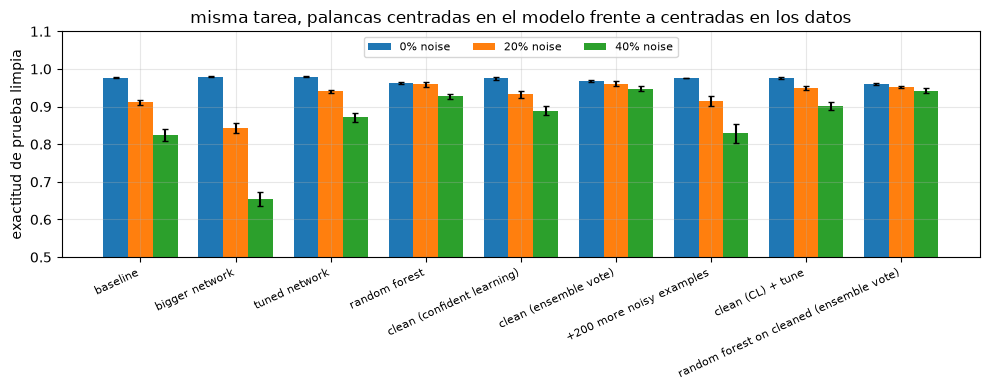

tiempo 69 s


In [4]:
GRID = [((64,), 1e-4), ((64,), 0.3), ((128,), 1e-4), ((128,), 0.3)]
def tune(X, y, seed):
    best = max(GRID, key=lambda g: cross_val_score(mlp(seed, g[0], g[1]), X, y, cv=3).mean())
    return mlp(seed, best[0], best[1]).fit(X, y), best

def contest_task(args):
    rate, seed = args
    yn = flip_sym(ytr, rate, 500 + seed)
    Xe, ye = X_pool[1000:], flip_sym(y_pool[1000:], rate, 600 + seed)
    sc = lambda m: m.score(X_test, y_test)
    r = {}
    r["baseline"] = sc(mlp(seed).fit(Xtr, yn))
    r["bigger network"] = sc(mlp(seed, (256, 256)).fit(Xtr, yn))
    r["tuned network"] = sc(tune(Xtr, yn, seed)[0])
    r["random forest"] = sc(RandomForestClassifier(300, random_state=seed, n_jobs=1).fit(Xtr, yn))
    ps = ens_oof(Xtr, yn, seed)
    keep = ~cl_flag(ps["mlp"], yn); keep2 = ~ens_flag(ps, yn)
    r["clean (confident learning)"] = sc(mlp(seed).fit(Xtr[keep], yn[keep]))
    r["clean (ensemble vote)"] = sc(mlp(seed).fit(Xtr[keep2], yn[keep2]))
    r["random forest on cleaned (ensemble vote)"] = sc(RandomForestClassifier(300, random_state=seed, n_jobs=1).fit(Xtr[keep2], yn[keep2]))
    r["+200 more noisy examples"] = sc(mlp(seed).fit(np.vstack([Xtr, Xe]), np.concatenate([yn, ye])))
    r["clean (CL) + tune"] = sc(tune(Xtr[keep], yn[keep], seed)[0])
    r["_removed"] = int((~keep).sum()); r["_removed_ens"] = int((~keep2).sum())
    return r

t0 = time.time()
crates = [0.0, 0.2, 0.4]
jobs = [(r, s) for r in crates for s in range(8)]
cres = dict(zip(jobs, pmap(contest_task, jobs)))
arms = ["baseline", "bigger network", "tuned network", "random forest", "clean (confident learning)", "clean (ensemble vote)", "+200 more noisy examples", "clean (CL) + tune", "random forest on cleaned (ensemble vote)"]
tab = pd.DataFrame({f"{r:.0%} noise": {a: f"{np.mean([cres[(r, s)][a] for s in range(8)]):.3f} ± {np.std([cres[(r, s)][a] for s in range(8)]):.3f}" for a in arms} for r in crates})
print("exactitud de prueba limpia, media ± desv. típ. de 8 semillas")
print(tab.to_string())
print("ejemplos eliminados al limpiar (media), aprendizaje confiado / voto del conjunto:", {f"{r:.0%}": (int(np.mean([cres[(r, s)]["_removed"] for s in range(8)])), int(np.mean([cres[(r, s)]["_removed_ens"] for s in range(8)]))) for r in crates})

fig, ax = plt.subplots(figsize=(10, 4))
w = 0.26
for i, r in enumerate(crates):
    m = [np.mean([cres[(r, s)][a] for s in range(8)]) for a in arms]; e = [np.std([cres[(r, s)][a] for s in range(8)]) for a in arms]
    ax.bar(np.arange(len(arms)) + (i - 1) * w, m, w, yerr=e, capsize=2, label=f"{r:.0%} noise")
ax.set_xticks(range(len(arms))); ax.set_xticklabels(arms, rotation=25, ha="right", fontsize=8)
ax.set_ylim(0.5, 1.1); ax.set_ylabel("exactitud de prueba limpia"); ax.legend(loc="upper center", ncol=3, fontsize=8); ax.set_title("misma tarea, palancas centradas en el modelo frente a centradas en los datos")
plt.tight_layout(); plt.show()
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** La tesis recibe un veredicto mixto, y los detalles importan. **Con un 20 % y un 40 % de ruido la palanca centrada en los datos fue tan grande como cualquier palanca del modelo que probamos, o mayor.** Limpiar con el voto del conjunto de modelos usando la misma red base llega a 0,961 y 0,947 frente a 0,911 y 0,824 de la base sin tocar (ganancias de 5 y 12 puntos); limpiar con aprendizaje confiado da 0,933 y 0,889. **Recoger 200 ejemplos más con el mismo ruido no hizo nada** (0,915 y 0,829, dentro del ruido de semillas de la base): más datos de la misma mala calidad no son un remedio. Del lado del modelo, **hacer la red mayor salió mal** (0,843 y 0,655) porque memoriza ruido, **ajustar** la anchura y la penalización L2 con las etiquetas ruidosas recuperó parte de la pérdida (0,941 y 0,872, la rejilla elige la penalización fuerte), y **cambiar la familia de modelos a un bosque aleatorio** recuperó casi todo sin trabajo alguno con los datos (0,959 y 0,927). Así, un cambio barato centrado en el modelo, una familia tolerante al ruido, queda estadísticamente empatado con limpiar con un 20 % de ruido (0,959 frente a 0,961, desviación típica 0,006) y 2 puntos por detrás con un 40 %. Combinar las palancas no se acumuló: un bosque con datos limpiados (0,952 y 0,942) no es mejor que la red limpiada, porque al bosque el ruido no le hacía mucho daño desde el principio. **Con ruido cero** nada del lado de los datos ayuda y los limpiadores perjudican ligeramente: eliminan 5 (aprendizaje confiado) y 22 (voto del conjunto) ejemplos de 1000 que de hecho estaban bien, y la exactitud pasa de 0,977 a 0,975 y 0,968; la red mayor o ajustada gana de 0,2 a 0,3 puntos, cerca del suelo de ruido. En resumen: si las etiquetas son ruidosas, arregla las etiquetas o elige un modelo robusto antes de gastar en capacidad; si las etiquetas son limpias, la palanca centrada en los datos no tiene nada que ofrecer en esta tarea. Límites: probamos un puñado de opciones centradas en el modelo (un especialista podría añadir pérdidas robustas, parada temprana, suavizado de etiquetas, ejercicio 3), un solo tipo de ruido y una tarea donde incluso la base limpia está en el 97,7 %.

## 5. Calidad de la anotación: acuerdo, ambigüedad, guías

Las etiquetas vienen de personas (o de otros modelos), y las personas discrepan. Dos preguntas: ¿cómo **medimos** la calidad de un proceso de etiquetado y cómo la **mejoramos**?

**El kappa de Cohen.** El acuerdo bruto entre dos anotadores exagera la calidad, porque parte del acuerdo ocurre por azar, sobre todo cuando domina una clase. El kappa de Cohen lo corrige:

$$\kappa = \frac{p_o - p_e}{1 - p_e},$$

donde $p_o$ es la fracción observada de acuerdo y $p_e$ el acuerdo esperado si ambos anotadores etiquetaran al azar con sus propias frecuencias de clase. $\kappa = 1$ es acuerdo perfecto, $0$ es nivel de azar. Una lectura habitual (y discutida): por debajo de 0,4 débil, de 0,6 a 0,8 sustancial, por encima de 0,8 casi perfecto.

Simulamos tres anotadores que etiquetan las 1000 imágenes de entrenamiento. Cada uno tiene una tasa de error (8 %, 12 %, 16 %) pero sus errores no son uniformes: un anotador confunde un dígito con un dígito **parecido** mucho más a menudo que con uno sin relación. Obtenemos el "parecido" de los datos (similitud del coseno entre las imágenes medias de dos clases), así que la ambigüedad es una propiedad de los datos y no algo que hayamos escrito a mano. Los anotadores reales además comparten errores sistemáticos, lo que hace que los votos por mayoría reales ayuden menos de lo que sugiere la simulación independiente de abajo.

Luego preguntamos qué aportan **mejores guías**. Una guía que dice a los anotadores exactamente cómo separar los cinco pares más confundibles reduce un 70 % los errores en esos pares (una suposición que hacemos explícita, porque escribir guías no es gratis y puede no funcionar).

pares de clases más parecidos (similitud del coseno de las medias de clase): [(1, 8, 0.93), (3, 9, 0.93), (8, 9, 0.9), (3, 8, 0.9), (2, 8, 0.9)]

=== guías originales ===
exactitud frente a la verdad: anotadores [0.923, 0.886, 0.821] mayoría de 3: 0.969
acuerdo bruto por pares: {(0, 1): 0.818, (0, 2): 0.767, (1, 2): 0.733}
kappa de Cohen por pares: {(0, 1): 0.798, (0, 2): 0.741, (1, 2): 0.703}


modelo entrenado con esas etiquetas, exactitud de prueba limpia: {'annotator 1 (8 % errors)': 0.94, 'annotator 3 (16 % errors)': 0.911, 'majority of 3': 0.96, 'truth': 0.976}

=== con guías mejoradas ===
exactitud frente a la verdad: anotadores [0.944, 0.906, 0.864] mayoría de 3: 0.985
acuerdo bruto por pares: {(0, 1): 0.854, (0, 2): 0.817, (1, 2): 0.79}
kappa de Cohen por pares: {(0, 1): 0.838, (0, 2): 0.797, (1, 2): 0.767}


modelo entrenado con esas etiquetas, exactitud de prueba limpia: {'annotator 1 (8 % errors)': 0.935, 'annotator 3 (16 % errors)': 0.926, 'majority of 3': 0.961, 'truth': 0.976}


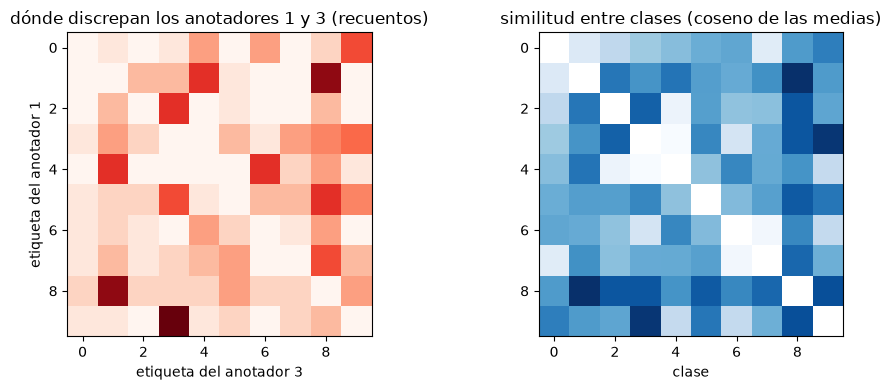

correlación de rangos entre desacuerdo y similitud de clases: 0.84
clase rara (prevalencia del 5 %), dos anotadores con 96 % de acierto: acuerdo bruto 0.925, kappa 0.529
tiempo 6 s


In [5]:
cm_ = np.array([X_ALL[Y_ALL == c].mean(0) for c in range(K)])
cm_ /= np.linalg.norm(cm_, axis=1, keepdims=True)
SIM = cm_ @ cm_.T                                           # similitud del coseno de las imágenes medias de cada clase
off = SIM.copy(); np.fill_diagonal(off, -1)
pairs_sorted = sorted([(off[i, j], i, j) for i in range(K) for j in range(i + 1, K)], reverse=True)
print("pares de clases más parecidos (similitud del coseno de las medias de clase):", [(i, j, round(float(s), 2)) for s, i, j in pairs_sorted[:5]])

def confusion_for(err, guideline=False, beta=25.0):
    W = np.exp(beta * (SIM - 1)); np.fill_diagonal(W, 0)
    W /= W.sum(1, keepdims=True)
    C = err * W
    if guideline:                                            # las guías aclaran los 5 pares más confundibles: esos errores bajan un 70 %
        for s, i, j in pairs_sorted[:5]:
            C[i, j] *= 0.3; C[j, i] *= 0.3
    np.fill_diagonal(C, 0); np.fill_diagonal(C, 1 - C.sum(1))
    return C

def annotate(y, errs, seed, guideline=False):
    r = np.random.default_rng(seed); out = []
    for e in errs:
        C = confusion_for(e, guideline); cum = C[y].cumsum(1)
        out.append((r.random(len(y))[:, None] > cum).sum(1).clip(0, K - 1))
    return np.stack(out)

def majority(A):
    cnt = np.zeros((A.shape[1], K))
    for a in range(A.shape[0]):
        cnt[np.arange(A.shape[1]), A[a]] += 1 + (1e-3 if a == 0 else 0)      # los empates van al primer anotador
    return cnt.argmax(1)

errs = [0.08, 0.12, 0.16]
t0 = time.time()
for guideline in [False, True]:
    A = annotate(ytr, errs, 7, guideline); mv = majority(A)
    print(f"\n=== {'con guías mejoradas' if guideline else 'guías originales'} ===")
    print("exactitud frente a la verdad: anotadores", [round(float((a == ytr).mean()), 3) for a in A], "mayoría de 3:", round(float((mv == ytr).mean()), 3))
    pk = {(i, j): cohen_kappa_score(A[i], A[j]) for i in range(3) for j in range(i + 1, 3)}
    pa = {(i, j): float((A[i] == A[j]).mean()) for i in range(3) for j in range(i + 1, 3)}
    print("acuerdo bruto por pares:", {k: round(v, 3) for k, v in pa.items()})
    print("kappa de Cohen por pares:", {k: round(v, 3) for k, v in pk.items()})
    acc_ = {}
    for name, lab in [("annotator 1 (8 % errors)", A[0]), ("annotator 3 (16 % errors)", A[2]), ("majority of 3", mv), ("truth", ytr)]:
        acc_[name] = np.mean([mlp(s).fit(Xtr, lab).score(X_test, y_test) for s in range(3)])
    print("modelo entrenado con esas etiquetas, exactitud de prueba limpia:", {k: round(float(v), 3) for k, v in acc_.items()})
    if not guideline:
        conf = np.zeros((K, K))
        for i, j in zip(A[0], A[2]):
            conf[i, j] += 1
        np.fill_diagonal(conf, 0); pass

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
im = ax[0].imshow(conf, cmap="Reds"); ax[0].set_title("dónde discrepan los anotadores 1 y 3 (recuentos)"); ax[0].set_xlabel("etiqueta del anotador 3"); ax[0].set_ylabel("etiqueta del anotador 1"); ax[0].grid(False)
S2 = SIM.copy(); np.fill_diagonal(S2, np.nan)
ax[1].imshow(S2, cmap="Blues"); ax[1].set_title("similitud entre clases (coseno de las medias)"); ax[1].set_xlabel("clase"); ax[1].grid(False)
plt.tight_layout(); plt.show()
iu = np.triu_indices(K, 1)
print("correlación de rangos entre desacuerdo y similitud de clases:", round(float(stats.spearmanr((conf + conf.T)[iu], SIM[iu])[0]), 2))

# por qué kappa y no el acuerdo bruto: dos buenos anotadores con una clase rara
r = np.random.default_rng(0); truth = (r.random(5000) < 0.05).astype(int)
a1 = np.where(r.random(5000) < 0.04, 1 - truth, truth); a2 = np.where(r.random(5000) < 0.04, 1 - truth, truth)
print(f"clase rara (prevalencia del 5 %), dos anotadores con 96 % de acierto: acuerdo bruto {np.mean(a1 == a2):.3f}, kappa {cohen_kappa_score(a1, a2):.3f}")
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** Los tres anotadores puntúan 0,92, 0,89 y 0,82 frente a la verdad, y su voto por mayoría 0,97. El kappa de Cohen por pares es de 0,70 a 0,80 frente a un acuerdo bruto de 0,73 a 0,82: con diez clases equilibradas el acuerdo por azar es de solo 0,1 aproximadamente, así que el kappa y el acuerdo bruto se parecen. El ejemplo de la clase rara muestra cuándo no: dos anotadores con un 96 % de acierto cada uno coinciden en el 92,5 % de los elementos y sin embargo tienen un kappa de solo 0,53, porque la mayor parte de ese acuerdo es la clase mayoritaria, fácil. El desacuerdo está **concentrado en las clases parecidas** (correlación de rangos de 0,84 entre los recuentos de desacuerdo de los anotadores y la similitud de clases derivada de los datos), que es donde mejores guías y una segunda mirada rinden. La calidad de las etiquetas pasa directamente al modelo: entrenado con el anotador 1 llega a 0,940, con el anotador 3 a 0,911, con el voto por mayoría a 0,960, con la verdad a 0,976. El voto por mayoría recupera la mayor parte de la diferencia por tres veces el coste de etiquetado. Las **guías mejoradas** (los cinco pares más confundibles con un 70 % menos de error, una suposición que elegimos) suben los kappa a 0,77 a 0,84 y la exactitud de la mayoría a 0,985, pero las ganancias en el modelo son pequeñas: 0,926 frente a 0,911 para el anotador más débil (3 semillas, cerca de un punto de dispersión, así que solo sugerente) y ningún cambio visible para el mejor anotador ni para el voto por mayoría (0,935 frente a 0,940; 0,961 frente a 0,960). Dos salvedades: los anotadores simulados se equivocan de forma independiente, lo que favorece al voto por mayoría porque los anotadores reales comparten errores sistemáticos; y en un proyecto real una revisión de las guías hay que probarla como aquí, con una muestra reetiquetada, nunca darla por supuesta.

## 6. Fugas, duplicados y particiones por grupos

Una **fuga de datos** (data leakage) significa que información de fuera de los datos de entrenamiento (normalmente del conjunto de prueba, o del futuro) se cuela en el entrenamiento, de modo que la puntuación de prueba es optimista y el modelo desplegado decepciona. Dos formas habituales:

* **Fuga por duplicados y casi duplicados.** El mismo elemento, o una copia ligeramente cambiada (una foto reexportada, fotogramas sucesivos de un vídeo, varios escáneres de un mismo paciente, el mismo producto listado dos veces), cae en ambos lados de una partición aleatoria. Un modelo que memoriza puntúa bien en la copia de prueba sin haber aprendido nada general. El remedio es una **partición por grupos**: todas las copias de un mismo elemento subyacente quedan juntas en un lado.
* **Fuga por variable (objetivo).** Una columna está disponible en los datos de entrenamiento a causa de la etiqueta, no antes de ella (un campo que se rellena *después* del diagnóstico; una ruta de archivo que codifica la clase), y falta o es distinta en producción.

**Parte A, duplicados.** Elegimos 200 imágenes base del conjunto, hacemos 5 casi duplicados de cada una (la misma imagen más un poco de ruido de píxel, desviación típica 0,08), lo que da 1000 filas en 200 **grupos**, y medimos la puntuación de prueba de cuatro modelos con (i) una **partición aleatoria**, (ii) una **partición por grupos** y (iii) la referencia honesta, un conjunto de 597 imágenes nuevas nunca vistas. Después intentamos **encontrar los duplicados sin que nos digan los grupos**: distancias al vecino más cercano, un umbral y componentes conexas.

**Parte B, una variable que filtra.** Añadimos una columna que, en el laboratorio donde se recogieron los datos, es casi la propia clase (piensa en una "estación de escáner", con una estación por dígito), y medimos el modelo en el laboratorio y en el "despliegue", donde la columna no tiene relación con la clase.

In [6]:
t0 = time.time()
rL = np.random.default_rng(5)
base_idx = rL.choice(len(X_pool), 200, replace=False); copies = 5
Xd = np.vstack([np.clip(X_pool[i] + rL.normal(0, 0.08, (copies, 64)), 0, 1) for i in base_idx])
yd = np.repeat(y_pool[base_idx], copies); gd = np.repeat(np.arange(200), copies)

models6 = {"1-nearest-neighbour": lambda s: KNeighborsClassifier(1), "random forest": lambda s: RandomForestClassifier(100, random_state=s, n_jobs=1),
           "MLP": lambda s: mlp(s), "logistic regression": lambda s: logreg()}
def leak_task(seed):
    rs = np.random.default_rng(seed); perm = rs.permutation(len(Xd)); te_r, tr_r = perm[:200], perm[200:]
    tr_g, te_g = next(GroupShuffleSplit(1, test_size=0.2, random_state=seed).split(Xd, yd, gd))
    o = {}
    for n, mk in models6.items():
        o[n] = (mk(seed).fit(Xd[tr_r], yd[tr_r]).score(Xd[te_r], yd[te_r]),
                (m := mk(seed).fit(Xd[tr_g], yd[tr_g])).score(Xd[te_g], yd[te_g]),
                m.score(X_test, y_test))
    return o
L = pmap(leak_task, range(5))
print(f"{'modelo':22s} {'part. aleatoria':>15s} {'part. por grupos':>16s} {'imág. nuevas':>13s}  (media de 5 semillas; nuevas = modelo de la partición por grupos)")
for n in models6:
    v = np.array([l[n] for l in L]).mean(0)
    print(f"{n:22s} {v[0]:13.3f} {v[1]:12.3f} {v[2]:13.3f}")

# encontrar los duplicados sin los grupos
nn = NearestNeighbors(n_neighbors=2).fit(Xd); dist, ind = nn.kneighbors(Xd); d1, j1 = dist[:, 1], ind[:, 1]
same = gd[j1] == gd
D = pairwise_distances(Xd)
same_g = gd[:, None] == gd[None, :]
other = np.where(same_g, np.inf, D).min(1); copy_d = np.where(same_g & ~np.eye(len(Xd), dtype=bool), D, np.inf).min(1)
print(f"\ndistancia a la copia verdadera más cercana: mediana {np.median(copy_d):.2f}; a la imagen más cercana de otro grupo: mediana {np.median(other):.2f}, percentil 1 {np.percentile(other, 1):.2f}")
iu = np.triu_indices(len(Xd), 1); true_pair = (gd[:, None] == gd[None, :])[iu]
best = None
print(f"{'umbral':>9s} {'precisión':>10s} {'exhaust.':>8s} {'F1':>6s}")
for tau in [0.6, 0.9, 1.2, 1.5, 1.8, 2.1]:
    pr = D[iu] < tau; tp = (pr & true_pair).sum(); p = tp / max(pr.sum(), 1); rc = tp / true_pair.sum(); f = 2 * p * rc / max(p + rc, 1e-9)
    print(f"{tau:9.1f} {p:10.3f} {rc:8.3f} {f:6.3f}")
    if best is None or f > best[1]:
        best = (tau, f)
tau = best[0]
ii, jj = np.where(np.triu(D < tau, 1))
ncomp, found = connected_components(coo_matrix((np.ones(len(ii)), (ii, jj)), shape=(len(Xd),) * 2), directed=False)
print(f"umbral elegido {tau} (mejor F1 en una muestra etiquetada de pares): {ncomp} grupos encontrados, número verdadero 200")
fr = []
for s in range(5):
    tr_f, te_f = next(GroupShuffleSplit(1, test_size=0.2, random_state=s).split(Xd, yd, found))
    fr.append(KNeighborsClassifier(1).fit(Xd[tr_f], yd[tr_f]).score(Xd[te_f], yd[te_f]))
print(f"1-NN con los grupos que descubrimos nosotros: {np.mean(fr):.3f}   (grupos verdaderos: {np.mean([l['1-nearest-neighbour'][1] for l in L]):.3f}, partición aleatoria: {np.mean([l['1-nearest-neighbour'][0] for l in L]):.3f})")

# ¿cuántos casi duplicados cruzan la partición entrenamiento/prueba de los dígitos originales?
dtp, _ = NearestNeighbors(n_neighbors=1).fit(X_pool).kneighbors(X_test)
print(f"dígitos originales, imagen de prueba a su imagen de entrenamiento más cercana: la más cercana {dtp.min():.2f}, imágenes de prueba más cerca de 0,6: {int((dtp[:, 0] < 0.6).sum())}, más cerca de {tau}: {int((dtp[:, 0] < tau).sum())} de {len(X_test)}")

# Parte B: una variable que filtra
r2 = np.random.default_rng(1)
leak = lambda y: (y + r2.normal(0, 0.1, len(y)))[:, None]
Xl_tr, Xl_te = np.hstack([Xtr, leak(ytr)]), np.hstack([X_test, leak(y_test)])
Xl_dep = np.hstack([X_test, r2.uniform(0, 9, (len(X_test), 1))])          # en el despliegue la columna no significa nada
rf_leak = RandomForestClassifier(200, random_state=0, n_jobs=1).fit(Xl_tr, ytr)
rf_clean = RandomForestClassifier(200, random_state=0, n_jobs=1).fit(Xtr, ytr)
print(f"\nbosque aleatorio CON la columna que filtra: prueba de laboratorio {rf_leak.score(Xl_te, y_test):.3f}, despliegue {rf_leak.score(Xl_dep, y_test):.3f}")
print(f"bosque aleatorio SIN la columna          : prueba de laboratorio {rf_clean.score(X_test, y_test):.3f}, despliegue {rf_clean.score(X_test, y_test):.3f}")
imp = rf_leak.feature_importances_
print(f"importancia de la columna que filtra: {imp[-1]:.3f} (los 64 píxeles tienen de media {imp[:-1].mean():.4f} cada uno)")
print(f"tiempo {time.time() - t0:.0f} s")

modelo                 part. aleatoria part. por grupos  imág. nuevas  (media de 5 semillas; nuevas = modelo de la partición por grupos)
1-nearest-neighbour            1.000        0.957         0.950
random forest                  1.000        0.917         0.933
MLP                            1.000        0.938         0.924
logistic regression            0.992        0.933         0.921

distancia a la copia verdadera más cercana: mediana 0.62; a la imagen más cercana de otro grupo: mediana 1.37, percentil 1 0.79
   umbral  precisión exhaust.     F1
      0.6      1.000    0.136  0.239
      0.9      0.986    0.997  0.991
      1.2      0.750    1.000  0.857
      1.5      0.367    1.000  0.537
      1.8      0.172    1.000  0.294
      2.1      0.088    1.000  0.162
umbral elegido 0.9 (mejor F1 en una muestra etiquetada de pares): 196 grupos encontrados, número verdadero 200
1-NN con los grupos que descubrimos nosotros: 0.922   (grupos verdaderos: 0.957, partición aleatoria: 1.000)


bosque aleatorio CON la columna que filtra: prueba de laboratorio 0.998, despliegue 0.911
bosque aleatorio SIN la columna          : prueba de laboratorio 0.956, despliegue 0.956
importancia de la columna que filtra: 0.177 (los 64 píxeles tienen de media 0.0129 cada uno)
tiempo 3 s


**Lectura.** **Parte A.** Con una partición aleatoria, todos los modelos puntúan 1,000 (la regresión logística 0,992): la copia de prueba de una imagen es casi idéntica a una copia de entrenamiento, así que se premia la memorización. Con una partición por grupos los mismos modelos puntúan de 0,92 a 0,96, y con 597 imágenes nuevas puntúan de 0,92 a 0,95, así que la estimación con partición por grupos está a menos de 1,5 puntos de la honesta (1 vecino más cercano 0,957 frente a 0,950, bosque 0,917 frente a 0,933, red 0,938 frente a 0,924, regresión logística 0,933 frente a 0,921) mientras que la estimación con partición aleatoria exagera de 4 a 8 puntos. Los propios duplicados son fáciles de encontrar cuando están tan cerca como los nuestros: la distancia mediana a la copia verdadera más cercana es 0,62, a la imagen más cercana de otro grupo 1,37 (percentil 1: 0,79), y un umbral de 0,9 encuentra los pares de copias con precisión 0,986 y exhaustividad 0,997. Las componentes conexas con ese umbral producen 196 grupos frente a 200 verdaderos. Usar los grupos que **descubrimos** dio 0,922 para el modelo de 1 vecino más cercano, frente a 0,957 con los grupos verdaderos: algunos grupos se fusionaron, lo que hace más difícil el conjunto de prueba, así que la estimación peca de conservadora; no aislamos el resto de la diferencia del ruido de la partición. Un umbral elegido con copias inyectadas no se traslada solo: en los dígitos originales la menor distancia entre prueba y entrenamiento es 0,50 y solo 6 de 597 imágenes de prueba están más cerca que el nivel 0,6 de nuestras copias (133 más cerca de 0,9), que son vecinos del mismo dígito y no duplicados. Esos 6 merecen una mirada a ojo, y la lección es **inspeccionar los pares más cercanos** en vez de fiarse de un número. **Parte B.** El bosque con la columna que filtra puntúa 0,998 en el laboratorio y 0,911 en el despliegue, frente a 0,956 en ambos para el modelo honesto: la fuga da 4 puntos en el laboratorio y cuesta 4,5 puntos donde importa. Su importancia (0,177) es 14 veces la de un píxel medio (0,0129), una comprobación barata que vale la pena en cada variable de cada proyecto. Los análogos reales son los escáneres de un mismo paciente a ambos lados de una partición, los fotogramas de un mismo vídeo o una ruta de archivo que codifica la clase.

## 7. Curvas de aprendizaje: ¿más datos o un modelo mejor?

Una **curva de aprendizaje** dibuja el error de un modelo en función del tamaño $n$ del conjunto de entrenamiento. Responde a la pregunta práctica "si pago por más etiquetas, ¿cuánto ganaré?" antes de pagar. Entrenamos con subconjuntos aleatorios del conjunto de tamaños de 30 a 1000 y probamos con las 597 imágenes de prueba limpias, con **20 subconjuntos aleatorios por tamaño** para poder dibujar una **banda de confianza** (la media más o menos 1,96 errores típicos, siendo el error típico la dispersión de las 20 ejecuciones dividida por $\sqrt{20}$). Salvedad: los subconjuntos de tamaño 1000 extraídos de un conjunto de 1200 se solapan mucho, así que la banda en el tamaño mayor es demasiado estrecha.

Dos lecturas de una curva:

* **Diferencia entre el error de entrenamiento y el de prueba**: una diferencia grande significa que el modelo está limitado por los datos (más datos o más regularización ayudan); un error de entrenamiento que ya es alto significa que el modelo está limitado por la capacidad o por el ruido de las etiquetas (más datos del mismo tipo no ayudarán).
* **Forma**: el error de prueba suele seguir una **ley de potencias** $\varepsilon(n) = a\,n^{-b} + c$, donde $c$ es el suelo de error que los datos infinitos no eliminarían (ruido, límites del modelo), $a$ una escala y $b > 0$ la tasa. La ajustamos solo con los tamaños hasta 500 y **comprobamos la predicción en $n = 1000$**, que también medimos. Un ajuste que no puede predecir un punto que no ha visto no debería usarse para planificar una compra de datos.

Dibujamos curvas para dos modelos, y para la red entrenada con etiquetas con un 30 % de ruido simétrico, donde el suelo debería verse claramente más alto.

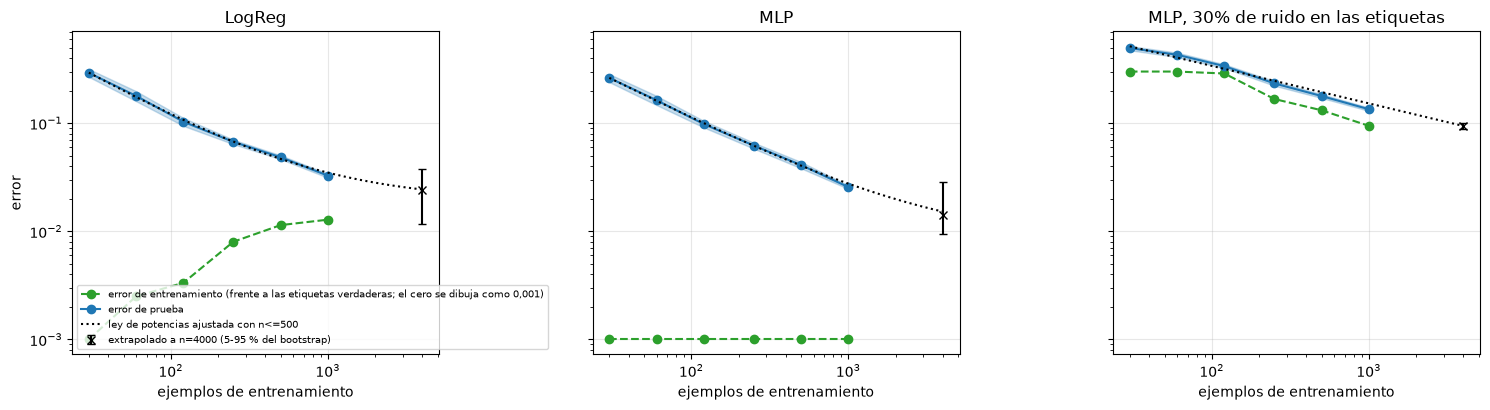

modelo   ruido  suelo c  tasa b  err@500  err@1000 medido  ajuste predice @1000        banda 90%   extrapolado @4000  err entren.@1000
LogReg      0%    0.019    0.82    0.048       0.033 ±0.001                0.035 [0.028,0.043]    0.024 [0.012,0.037]           0.013
MLP         0%    0.008    0.73    0.041       0.026 ±0.001                0.028 [0.024,0.036]    0.014 [0.009,0.028]           0.000
MLP        30%    0.000    0.35    0.178       0.135 ±0.005                0.152 [0.145,0.160]    0.094 [0.088,0.101]           0.094
tiempo 9 s


In [7]:
t0 = time.time()
sizes = [30, 60, 120, 250, 500, 1000]; reps = 20
def lc_task(args):
    name, n, rep, rho = args
    rs = np.random.default_rng(10000 * rep + n); idx = rs.choice(len(X_pool), n, replace=False)
    y = flip_sym(y_pool[idx], rho, 7 * rep + n) if rho else y_pool[idx]
    m = (logreg() if name == "LogReg" else mlp(rep)).fit(X_pool[idx], y)
    return 1 - m.score(X_pool[idx], y_pool[idx]), 1 - m.score(X_test, y_test)
curves = {("LogReg", 0): None, ("MLP", 0): None, ("MLP", 0.3): None}
jobs = [(nm, n, rp, rho) for (nm, rho) in curves for n in sizes for rp in range(reps)]
lc = dict(zip(jobs, pmap(lc_task, jobs)))
def power(n, a, b, c):
    return a * np.power(n, -b) + c

fig, ax = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
summary = []
for a_, (nm, rho) in zip(ax, curves):
    tr = np.array([[lc[(nm, n, rp, rho)][0] for rp in range(reps)] for n in sizes])
    te = np.array([[lc[(nm, n, rp, rho)][1] for rp in range(reps)] for n in sizes])
    m, se = te.mean(1), te.std(1, ddof=1) / np.sqrt(reps)
    a_.plot(sizes, np.maximum(tr.mean(1), 1e-3), "C2--o", label="error de entrenamiento (frente a las etiquetas verdaderas; el cero se dibuja como 0,001)")
    a_.plot(sizes, m, "C0-o", label="error de prueba"); a_.fill_between(sizes, m - 1.96 * se, m + 1.96 * se, color="C0", alpha=0.25)
    fit_n = np.array(sizes[:5]); boots = []
    rb = np.random.default_rng(0)
    for _ in range(200):
        pick = rb.integers(0, reps, reps); mb = te[:5][:, pick].mean(1)
        try:
            p, _ = curve_fit(power, fit_n, mb, p0=[1.0, 0.5, 0.01], bounds=([0, 0.05, 0], [50, 3, 0.5]), maxfev=5000)
            boots.append(power(np.array([1000, 4000]), *p))
        except Exception:
            pass
    boots = np.array(boots); p, _ = curve_fit(power, fit_n, m[:5], p0=[1.0, 0.5, 0.01], bounds=([0, 0.05, 0], [50, 3, 0.5]), maxfev=5000)
    xs = np.logspace(np.log10(30), np.log10(4000), 60); a_.plot(xs, power(xs, *p), "k:", label=f"ley de potencias ajustada con n<=500")
    a_.errorbar([4000], [np.median(boots[:, 1])], [[np.median(boots[:, 1]) - np.percentile(boots[:, 1], 5)], [np.percentile(boots[:, 1], 95) - np.median(boots[:, 1])]], fmt="kx", capsize=3, label="extrapolado a n=4000 (5-95 % del bootstrap)")
    a_.set_xscale("log"); a_.set_yscale("log"); a_.set_xlabel("ejemplos de entrenamiento"); a_.set_title(f"{nm}" + (f", {rho:.0%} de ruido en las etiquetas" if rho else ""))
    summary.append((nm, rho, p, m[4], m[5], se[5], power(1000, *p), np.percentile(boots[:, 0], [5, 95]), np.median(boots[:, 1]), np.percentile(boots[:, 1], [5, 95]), tr.mean(1)[5]))
ax[0].set_ylabel("error"); ax[0].legend(fontsize=7)
plt.tight_layout(); plt.show()
print(f"{'modelo':8s} {'ruido':>5s} {'suelo c':>8s} {'tasa b':>7s} {'err@500':>8s} {'err@1000 medido':>16s} {'ajuste predice @1000':>21s} {'banda 90%':>16s} {'extrapolado @4000':>19s} {'err entren.@1000':>17s}")
for nm, rho, p, e500, e1000, se1000, pred, band, e4000, b4000, trn in summary:
    print(f"{nm:8s} {rho:5.0%} {p[2]:8.3f} {p[1]:7.2f} {e500:8.3f} {e1000:11.3f} ±{1.96 * se1000:.3f} {pred:20.3f} [{band[0]:.3f},{band[1]:.3f}] {e4000:8.3f} [{b4000[0]:.3f},{b4000[1]:.3f}] {trn:15.3f}")
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** El error de prueba de ambos modelos cae casi linealmente en el gráfico log-log en todo el rango, así que ninguno ha llegado a una meseta con 1000 ejemplos: la red pasa de 0,041 con 500 a 0,026 con 1000 (un 37 % menos al duplicar los datos) y la regresión logística de 0,048 a 0,033. La red es mejor que la regresión logística en todos los tamaños, y su error de entrenamiento es cero mientras el de prueba es del 2,6 %, la firma de un modelo limitado por los datos y no por la capacidad: **aquí, recoger más datos limpios debería ayudar**, en torno a un tercio por cada duplicación según la pendiente medida. El ajuste de ley de potencias (suelo $c$ = 0,008 para la red y 0,019 para la regresión logística, tasa $b$ de 0,7 a 0,8 aproximadamente) predijo correctamente el tamaño 1000 reservado en los dos casos limpios: las predicciones 0,035 y 0,028 caen dentro de sus bandas bootstrap del 90 % y a menos de 0,2 puntos de las mediciones 0,033 y 0,026. En el caso ruidoso **falló**: predijo 0,152 con banda de 0,145 a 0,160 frente a 0,135 medido, así que la extrapolación a 4000 (0,094) es demasiado pesimista y su banda demasiado estrecha; la ley de potencias ajustada no tenía la forma correcta para esa curva, que cae con una pendiente más suave ($b$ = 0,35). Leyendo el gráfico, 1000 ejemplos con un 30 % de ruido valen aproximadamente 80 a 100 limpios. Las extrapolaciones a 4000 (0,024 y 0,014 con bandas anchas) son una guía del orden de magnitud, no una promesa. Salvedad: los subconjuntos de tamaño 1000 de un conjunto de 1200 se solapan mucho, así que la banda de ese tamaño es demasiado estrecha, y el juguete tiene una curva muy suave; las curvas de aprendizaje reales son más ruidosas y a menudo se curvan.

## 8. El valor de cada dato

No todos los ejemplos de entrenamiento valen lo mismo: unos llevan el patrón, otros son redundantes, otros están mal etiquetados y *perjudican*. La **valoración de datos** asigna a cada punto de entrenamiento un número por su contribución. Dos definiciones clásicas, con una **utilidad** $U(S)$ = exactitud de validación de un modelo entrenado con el subconjunto $S$ del conjunto de entrenamiento $D$ ($n = |D|$ puntos):

* **Dejar uno fuera** (LOO, leave-one-out): $v^{\text{LOO}}_i = U(D) - U(D \setminus \{i\})$. Barato ($n+1$ ajustes), pero si un punto tiene un gemelo, quitar cualquiera de los dos no cambia nada, así que ambos parecen inútiles.
* **Shapley de datos** (Ghorbani y Zou, 2019): la contribución marginal media $U(S \cup \{i\}) - U(S)$ del punto $i$ sobre **todos los órdenes** en que podrían ensamblarse los datos, el valor de Shapley de la teoría de juegos cooperativos,

$$v_i = \frac{1}{n}\sum_{S \subseteq D \setminus \{i\}} \binom{n-1}{|S|}^{-1} \big[U(S \cup \{i\}) - U(S)\big].$$

La suma tiene $2^{n-1}$ términos, así que la estimamos por **Monte Carlo sobre permutaciones aleatorias**: barajar los datos, añadir puntos de uno en uno y anotar la ganancia marginal de cada punto; promediar sobre muchos barajados (la variante de Monte Carlo *truncada* del artículo además se detiene pronto cuando la ganancia se vuelve despreciable, lo que omitimos porque nuestro conjunto es diminuto); usamos 240 permutaciones.

Juguete: el par de dígitos más difícil de los datos, 4 frente a 9. Conjunto de entrenamiento de 36 imágenes de las que 6 tienen **etiquetas cambiadas**; un conjunto de validación de 120 imágenes define $U$; las imágenes restantes son el conjunto de prueba. Comprobamos si el valor ordena los puntos cambiados al final, si **quitar los puntos de menor valor** mejora el modelo en el conjunto de prueba más que quitar puntos al azar, y si quitar los puntos de mayor valor perjudica.

U(los 36 puntos) = 0.925; los valores de Shapley suman 0.425 (eficiencia: U(todos) - U(vacío) = 0.425)
acuerdo entre dos mitades independientes de las permutaciones (Spearman): 0.79
AUROC de 'valor bajo = etiqueta cambiada':  LOO 0.72,  Shapley 1.00
valor medio de los 6 puntos cambiados: LOO -0.0014 frente a +0.0153 los demás;  Shapley -0.0454 frente a +0.0233 los demás
correlación de rangos LOO frente a Shapley: 0.55


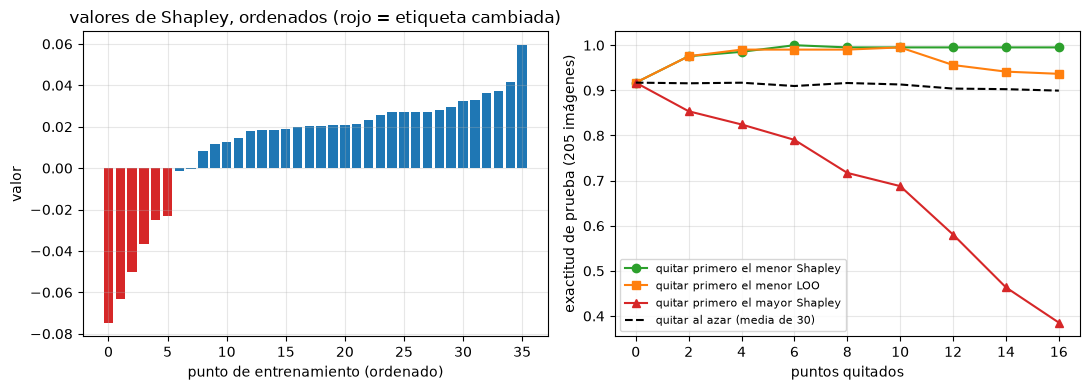

exactitud de prueba tras quitar k puntos, lowest Shapley first     {0: 0.917, 2: 0.976, 4: 0.985, 6: 1.0, 8: 0.995, 10: 0.995, 12: 0.995, 14: 0.995, 16: 0.995}
exactitud de prueba tras quitar k puntos, lowest LOO first         {0: 0.917, 2: 0.976, 4: 0.99, 6: 0.99, 8: 0.99, 10: 0.995, 12: 0.956, 14: 0.941, 16: 0.937}
exactitud de prueba tras quitar k puntos, highest Shapley first    {0: 0.917, 2: 0.854, 4: 0.824, 6: 0.79, 8: 0.717, 10: 0.688, 12: 0.58, 14: 0.463, 16: 0.385}
eliminación al azar (media de 30)                                                {0: 0.917, 2: 0.916, 4: 0.917, 6: 0.91, 8: 0.916, 10: 0.913, 12: 0.904, 14: 0.903, 16: 0.899}
tiempo 6 s


In [8]:
t0 = time.time()
m49 = np.isin(Y_ALL, [4, 9]); X49, y49 = X_ALL[m49], (Y_ALL[m49] == 9).astype(int)
r8 = np.random.default_rng(3); perm = r8.permutation(len(X49))
itr, iva, ite = perm[:36], perm[36:156], perm[156:]
Xv, yv_true = X49[itr], y49[itr]; yv = yv_true.copy()
flipped = r8.choice(36, 6, replace=False); yv[flipped] = 1 - yv[flipped]
Xval, yval, Xt49, yt49 = X49[iva], y49[iva], X49[ite], y49[ite]

def util(idx, Xs=None, ys=None):
    idx = np.asarray(idx, int)
    if len(idx) < 2 or len(np.unique(yv[idx])) < 2:
        return 0.5
    return LogisticRegression(max_iter=100).fit(Xv[idx], yv[idx]).score(Xval, yval)

full = np.arange(36); U_full = util(full)
loo = np.array([U_full - util(np.delete(full, i)) for i in range(36)])

def shap_task(args):
    seed, nperm = args
    rs = np.random.default_rng(seed); vals = np.zeros(36)
    for _ in range(nperm):
        p = rs.permutation(36); prev = 0.5
        for t in range(36):
            u = util(p[:t + 1]); vals[p[t]] += u - prev; prev = u
    return vals / nperm
parts = pmap(shap_task, [(s, 60) for s in range(4)])
shap = np.mean(parts, 0)
half_corr = stats.spearmanr(np.mean(parts[:2], 0), np.mean(parts[2:], 0))[0]
truth = np.zeros(36, bool); truth[flipped] = True
print(f"U(los 36 puntos) = {U_full:.3f}; los valores de Shapley suman {shap.sum():.3f} (eficiencia: U(todos) - U(vacío) = {U_full - 0.5:.3f})")
print(f"acuerdo entre dos mitades independientes de las permutaciones (Spearman): {half_corr:.2f}")
print(f"AUROC de 'valor bajo = etiqueta cambiada':  LOO {roc_auc_score(truth, -loo):.2f},  Shapley {roc_auc_score(truth, -shap):.2f}")
print(f"valor medio de los 6 puntos cambiados: LOO {loo[truth].mean():+.4f} frente a {loo[~truth].mean():+.4f} los demás;  Shapley {shap[truth].mean():+.4f} frente a {shap[~truth].mean():+.4f} los demás")
print(f"correlación de rangos LOO frente a Shapley: {stats.spearmanr(loo, shap)[0]:.2f}")

def test_after_removal(order, k):
    keep = np.setdiff1d(full, order[:k]);
    if len(np.unique(yv[keep])) < 2: return 0.5
    return LogisticRegression(max_iter=100).fit(Xv[keep], yv[keep]).score(Xt49, yt49)
ks = list(range(0, 17, 2))
low = np.argsort(shap); high = np.argsort(-shap); lo_loo = np.argsort(loo)
rand = np.mean([[test_after_removal(np.random.default_rng(s).permutation(36), k) for k in ks] for s in range(30)], 0)
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].bar(np.arange(36), shap[np.argsort(shap)], color=["C3" if truth[i] else "C0" for i in np.argsort(shap)]); ax[0].set_title("valores de Shapley, ordenados (rojo = etiqueta cambiada)"); ax[0].set_xlabel("punto de entrenamiento (ordenado)"); ax[0].set_ylabel("valor")
ax[1].plot(ks, [test_after_removal(low, k) for k in ks], "C2-o", label="quitar primero el menor Shapley")
ax[1].plot(ks, [test_after_removal(lo_loo, k) for k in ks], "C1-s", label="quitar primero el menor LOO")
ax[1].plot(ks, [test_after_removal(high, k) for k in ks], "C3-^", label="quitar primero el mayor Shapley")
ax[1].plot(ks, rand, "k--", label="quitar al azar (media de 30)")
ax[1].set_xlabel("puntos quitados"); ax[1].set_ylabel(f"exactitud de prueba ({len(yt49)} imágenes)"); ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()
for nm_, o_ in [("lowest Shapley first", low), ("lowest LOO first", lo_loo), ("highest Shapley first", high)]:
    print(f"exactitud de prueba tras quitar k puntos, {nm_:24s}", {k: round(float(test_after_removal(o_, k)), 3) for k in ks})
print(f"{'eliminación al azar (media de 30)':80s}", {k: round(float(v), 3) for k, v in zip(ks, rand)})
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** Los valores de Shapley suman la ganancia total $U(D) - U(\emptyset) = 0,425$ (la propiedad de eficiencia, una buena comprobación del estimador), y dos mitades independientes de las permutaciones ordenan los puntos con una correlación de Spearman de 0,79, así que la estimación es utilizable pero no exacta con 240 permutaciones. **Shapley colocó las 6 etiquetas cambiadas al final (AUROC 1,00); dejar uno fuera obtuvo 0,72**, y los dos órdenes coinciden solo moderadamente (correlación de rangos 0,55). Los puntos cambiados tienen un valor de Shapley medio de $-0,045$ frente a $+0,023$ de los demás. El experimento de eliminación muestra el valor práctico: quitar los 2, 4 y 6 puntos de menor valor sube la exactitud de prueba de 0,917 a 0,976, 0,985 y 1,000 (205 imágenes de prueba, así que una imagen son 0,5 puntos), mientras que quitar puntos al azar la deja en 0,90 a 0,92, y quitar los puntos de *mayor* valor la degrada de forma constante hasta 0,385 con 16 eliminaciones. Dejar uno fuera ayuda hasta 10 eliminaciones (0,995) y luego empieza a quitar puntos útiles (0,937 con 16), mientras que Shapley se queda en 0,995. La diferencia de coste es grande: 240 permutaciones por 36 ajustes, unos 8600 ajustes del modelo, frente a 37 de dejar uno fuera. Este juguete tiene 36 puntos y un modelo rápido; con conjuntos reales la suma exacta está fuera de alcance y se usan aproximaciones más baratas (Shapley por vecinos más cercanos, funciones de influencia o la dinámica de la pérdida de entrenamiento), así que el juguete muestra lo que una buena valoración *debería* encontrar, no que sea barata.

## 9. Aprendizaje activo

Las etiquetas son la parte cara. El **aprendizaje activo** deja que el modelo elija qué ejemplos sin etiquetar debe etiquetar a continuación una persona, en lugar de etiquetar al azar (Settles, 2009). El bucle: entrenar con lo etiquetado, puntuar el conjunto sin etiquetar, pedir etiquetas de los $b$ ejemplos más útiles (el **lote**), repetir. Estrategias:

* **aleatoria**: la base que todo método activo debe superar, y la que a menudo gana cuando el modelo es débil o el presupuesto es minúsculo;
* **incertidumbre (entropía)**: elegir ejemplos donde la distribución predicha está más dispersa, $H = -\sum_k p_k \ln p_k$;
* **margen**: elegir ejemplos donde las dos probabilidades de clase más altas están más cerca;
* **diversidad (k-centros)**: ignorar el modelo y elegir ejemplos lejos de todo lo ya etiquetado (elección voraz del punto más lejano), lo que cubre el espacio de entrada;
* **híbrida**: tomar los $5b$ más inciertos y elegir $b$ de ellos que estén lejos unos de otros (para que un lote no sean diez copias de la misma región confusa).

Empezamos con 20 etiquetas aleatorias, añadimos 10 por ronda hasta 200, con una regresión logística, sobre el conjunto de 1200 imágenes, puntuando en el conjunto de prueba limpio. Todas las curvas son la media de **20 semillas** (conjuntos iniciales distintos), con una banda del 90 %. El número principal es el **presupuesto de etiquetado** que cada estrategia necesita para alcanzar una exactitud objetivo, y el ahorro respecto a la aleatoria.

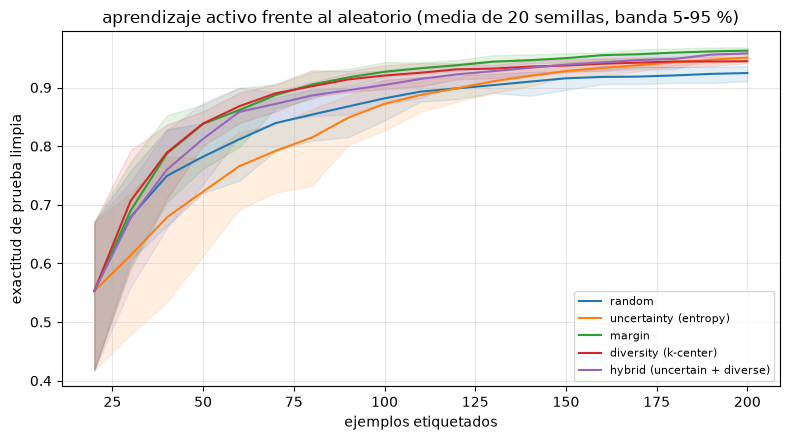

estrategia                       ex@60   ex@100   ex@200   etiquetas hasta 0,85  ahorro   etiquetas hasta 0,90  ahorro
random                           0.812    0.882    0.925                     80      0%                   130      0%
uncertainty (entropy)            0.766    0.872    0.951                    100    -25%                   130      0%
margin                           0.862    0.927    0.963                     60     25%                    80     38%
diversity (k-center)             0.868    0.921    0.945                     60     25%                    80     38%
hybrid (uncertain + diverse)     0.859    0.904    0.958                     60     25%                   100     23%
dispersión entre semillas (desv. típ. de la exactitud con 100 etiquetas): {'random': 0.022, 'uncertainty (entropy)': 0.029, 'margin': 0.008, 'diversity (k-center)': 0.013, 'hybrid (uncertain + diverse)': 0.019}
diferencia emparejada con la aleatoria con 100 etiquetas (media ± error típico, 

In [9]:
t0 = time.time()
D_pool = pairwise_distances(X_pool)
def kcenter(cand, lab, b):
    mind = D_pool[np.ix_(cand, lab)].min(1); pick = []
    for _ in range(b):
        j = int(mind.argmax()); pick.append(cand[j]); mind = np.minimum(mind, D_pool[cand, cand[j]])
    return pick

def al_task(args):
    strat, seed = args
    r = np.random.default_rng(seed); lab = list(r.choice(len(X_pool), 20, replace=False)); accs = []; budget = 200; b = 10
    while True:
        m = LogisticRegression(max_iter=200).fit(X_pool[lab], y_pool[lab]); accs.append(m.score(X_test, y_test))
        if len(lab) >= budget:
            break
        unl = np.setdiff1d(np.arange(len(X_pool)), lab)
        if strat == "random":
            pick = list(r.choice(unl, b, replace=False))
        elif strat == "diversity (k-center)":
            pick = kcenter(unl, np.array(lab), b)
        else:
            P = np.zeros((len(unl), K)); P[:, m.classes_] = m.predict_proba(X_pool[unl])
            if strat == "uncertainty (entropy)":
                pick = list(unl[np.argsort(-(-(P * np.log(P + 1e-12)).sum(1)))[:b]])
            elif strat == "margin":
                s = np.sort(P, 1); pick = list(unl[np.argsort(s[:, -1] - s[:, -2])[:b]])
            else:
                ent = -(P * np.log(P + 1e-12)).sum(1); cand = unl[np.argsort(-ent)[:5 * b]]
                pick = kcenter(cand, np.array(lab), b)
        lab += pick
    return accs

strats = ["random", "uncertainty (entropy)", "margin", "diversity (k-center)", "hybrid (uncertain + diverse)"]
jobs = [(s, sd) for s in strats for sd in range(20)]
al = dict(zip(jobs, pmap(al_task, jobs)))
grid = np.arange(20, 201, 10)
fig, ax = plt.subplots(figsize=(8, 4.5)); curves_al = {}
for i, s in enumerate(strats):
    A = np.array([al[(s, sd)] for sd in range(20)]); curves_al[s] = A
    ax.plot(grid, A.mean(0), color=f"C{i}", label=s); ax.fill_between(grid, np.percentile(A, 5, 0), np.percentile(A, 95, 0), color=f"C{i}", alpha=0.12)
ax.set_xlabel("ejemplos etiquetados"); ax.set_ylabel("exactitud de prueba limpia"); ax.legend(fontsize=8); ax.set_title("aprendizaje activo frente al aleatorio (media de 20 semillas, banda 5-95 %)")
plt.tight_layout(); plt.show()
print(f"{'estrategia':30s} {'ex@60':>7s} {'ex@100':>8s} {'ex@200':>8s}  {'etiquetas hasta 0,85':>21s} {'ahorro':>7s}  {'etiquetas hasta 0,90':>21s} {'ahorro':>7s}")
def first(A, thr):
    mm = A.mean(0); hit = np.where(mm >= thr)[0]
    return grid[hit[0]] if len(hit) else None
base = {t: first(curves_al["random"], t) for t in (0.85, 0.90)}
for s in strats:
    A = curves_al[s]; row = f"{s:30s} {A[:, 4].mean():7.3f} {A[:, 8].mean():8.3f} {A[:, -1].mean():8.3f} "
    for t in (0.85, 0.90):
        f = first(A, t)
        sv = (f"{1 - f / base[t]:7.0%}" if f and base[t] else "    n/a")
        row += f" {str(f) if f else '>200':>21s} {sv}"
    print(row)
print("dispersión entre semillas (desv. típ. de la exactitud con 100 etiquetas):", {s: round(float(curves_al[s][:, 8].std()), 3) for s in strats})
pdiff = {}
for s_ in strats[1:]:
    d = curves_al[s_][:, 8] - curves_al["random"][:, 8]            # misma semilla = mismo conjunto inicial etiquetado
    pdiff[s_] = f"{d.mean():+.3f} ± {d.std(ddof=1) / np.sqrt(len(d)):.3f} (p = {stats.ttest_rel(curves_al[s_][:, 8], curves_al['random'][:, 8]).pvalue:.3f})"
print("diferencia emparejada con la aleatoria con 100 etiquetas (media ± error típico, prueba t emparejada):", pdiff)
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** Promediando sobre 20 semillas, **el muestreo por margen y por diversidad alcanza 0,90 de exactitud con 80 etiquetas donde la aleatoria necesita 130**, un ahorro del 38 %, y 0,85 con 60 etiquetas frente a 80 (25 %); la híbrida ahorra un 25 % y un 23 %. Con 100 etiquetas las diferencias emparejadas con la aleatoria (mismas etiquetas iniciales por semilla) son $+0,045 \pm 0,006$ para el margen, $+0,039 \pm 0,005$ para la diversidad y $+0,023 \pm 0,007$ para la híbrida, con la dispersión entre semillas entre 0,8 y 2,9 puntos. **El muestreo simple por entropía no es mejor que el aleatorio** al principio (0,766 frente a 0,812 con 60 etiquetas, una diferencia emparejada con 100 etiquetas de $-0,009 \pm 0,009$): los diez ejemplos más inciertos están en la misma región confusa, así que un lote es redundante, y con 20 etiquetas la propia incertidumbre del modelo no es fiable (el problema del arranque en frío). Lo supera más tarde (0,951 frente a 0,925 con 200 etiquetas), lo que muestra que el orden de las estrategias depende del presupuesto. Nuestra híbrida, candidatos inciertos y luego elección del punto más lejano, no superó al margen ni a la diversidad pura en estos datos, así que "combínalas" es una hipótesis que probar y no una regla. Los presupuestos del primer cruce tienen una resolución de 10 etiquetas, lo que explica que dos estrategias con curvas distintas compartan un número. En qué se diferencia el juguete: un conjunto de 1200 imágenes y una regresión logística hacen la selección barata y el reentrenamiento instantáneo; los conjuntos reales tienen millones de elementos, los modelos tardan horas en reentrenarse, los anotadores se equivocan (sección 5) y el elemento que el modelo encuentra más incierto es también el más difícil de etiquetar para una persona.

## 10. Aumento de datos, datos sintéticos y colapso de modelos

El **aumento de datos** crea ejemplos de entrenamiento nuevos aplicando cambios que **no deberían cambiar la etiqueta**: desplazar un dígito un píxel, girarlo unos grados, añadir un poco de ruido. Inyecta conocimiento del dominio ("un 7 sigue siendo un 7 si se mueve un poco") y es la forma más barata de hacer crecer un conjunto pequeño. Su riesgo es justo ese conocimiento: un aumento que cambia la etiqueta (girar un 6 180 grados da un 9) enseña lo equivocado.

Los **datos sintéticos** van más lejos: se entrena un modelo generativo con los datos reales y se muestrean ejemplos nuevos de él. Es atractivo cuando los datos reales son escasos, privados o desequilibrados, pero solo puede recombinar lo que el generador aprendió, y **lo que no está en la muestra real no está en la sintética**.

El **colapso de modelos** (Shumailov et al., 2023, 2024) es lo que ocurre cuando esto se itera: el modelo $G_{t+1}$ se entrena con muestras generadas por $G_t$, que se entrenó con muestras generadas por $G_{t-1}$, y así sucesivamente. Cada generación estima una distribución a partir de una muestra finita, así que los sucesos raros (las colas) se pierden con cierta probabilidad, y una vez perdidos no vuelven. La distribución se estrecha y deriva. Importa porque los modelos a escala web se entrenan cada vez más con texto e imágenes que produjeron modelos anteriores. Un trabajo posterior (Gerstgrasser et al., 2024) mostró que **acumular** datos reales junto a los sintéticos, en lugar de sustituirlos, evita el colapso en su configuración.

Hacemos tres experimentos pequeños. **A**: aumentos con un modelo entrenado con 150 dígitos reales, incluido uno dañino. **B**: dígitos sintéticos muestreados de una gaussiana por clase ajustada a las mismas 150 imágenes. **C**: el juguete del colapso: una distribución unidimensional formada por un pico principal (85 % de la masa, centrado en 0) y un pico raro (15 %, centrado en 5); cada generación ajusta una mezcla de dos gaussianas a 60 puntos y la generación siguiente se entrena con 60 puntos muestreados de ella. Comparamos **sustituir** (entrenar solo con las muestras de la generación anterior), **acumular** (conservar la muestra real y todas las generaciones previas) y **20 % de real nuevo** (cada generación mezcla un 20 % de datos reales recién recogidos).

Partes A y B: exactitud de prueba limpia de un MLP (media ± desv. típ. de 10 semillas; cada aumento añade 6 copias modificadas de las 150 imágenes)
  150 real                                 0.914 ± 0.014
  + shifts of 1 pixel only                 0.908 ± 0.013
  + rotations up to 12 degrees only        0.904 ± 0.014
  + pixel noise only                       0.914 ± 0.012
  + all three                              0.890 ± 0.013
  + all three and 180 degree turns (changes labels) 0.875 ± 0.012
  + all three and mirror image (changes labels) 0.860 ± 0.015
  300 real (twice the labels)              0.951 ± 0.007
  150 real + 600 synthetic Gaussian        0.914 ± 0.006
  600 synthetic only                       0.909 ± 0.010


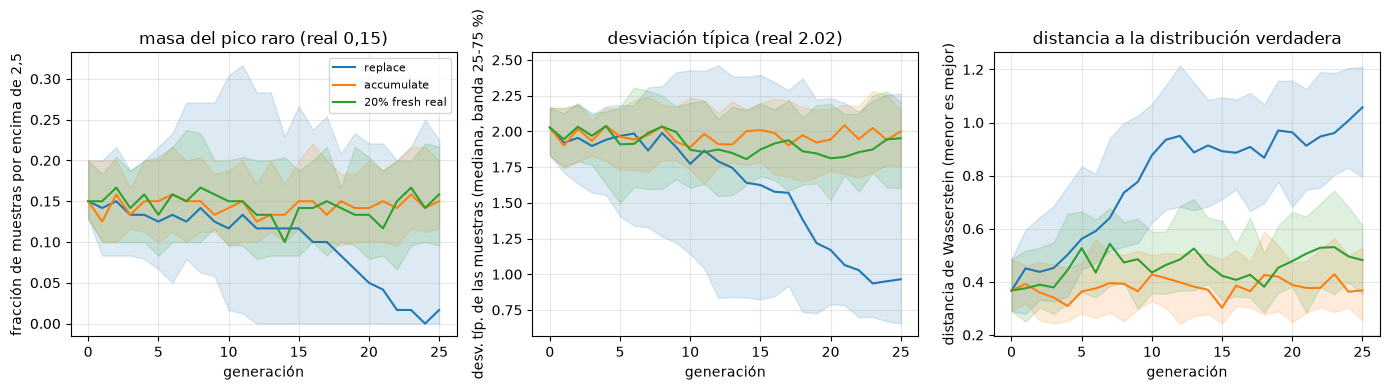

desv. típ. real de la mezcla: 2.02; masa rara real 0.154
régimen            masa rara gen0 gen25 media gen25 mediana ejec. con pico raro perdido desv gen0 gen25 med  W1 gen0 gen25 med
replace                     0.160       0.132         0.017                   20 of 40      1.99    0.96     0.41    1.06
accumulate                  0.160       0.153         0.150                    0 of 40      1.99    2.00     0.41    0.37
20% fresh real              0.160       0.168         0.158                    0 of 40      1.99    1.95     0.41    0.48
tiempo 11 s


In [10]:
t0 = time.time()
def augment(x, rs, kinds):
    im = x.reshape(8, 8)
    if "shift" in kinds: im = ndimage.shift(im, rs.integers(-1, 2, 2), order=1, mode="constant")
    if "rotate" in kinds: im = ndimage.rotate(im, rs.uniform(-12, 12), reshape=False, order=1, mode="constant")
    if "noise" in kinds: im = im + rs.normal(0, 0.05, im.shape)
    if "flip180" in kinds and rs.random() < 0.5: im = np.rot90(im, 2)
    if "mirror" in kinds and rs.random() < 0.5: im = im[:, ::-1]
    return np.clip(im, 0, 1).ravel()

def aug_task(seed):
    rs = np.random.default_rng(seed); idx = rs.choice(len(X_pool), 150, replace=False); X0, y0 = X_pool[idx], y_pool[idx]
    out = {}
    out["150 real"] = mlp(seed).fit(X0, y0).score(X_test, y_test)
    for name, kinds in [("+ shifts of 1 pixel only", ["shift"]), ("+ rotations up to 12 degrees only", ["rotate"]), ("+ pixel noise only", ["noise"]),
                        ("+ all three", ["shift", "rotate", "noise"]), ("+ all three and 180 degree turns (changes labels)", ["shift", "rotate", "noise", "flip180"]),
                        ("+ all three and mirror image (changes labels)", ["shift", "rotate", "noise", "mirror"])]:
        Xa = np.vstack([X0] + [np.array([augment(x, rs, kinds) for x in X0]) for _ in range(6)]); ya = np.tile(y0, 7)
        out[name] = mlp(seed).fit(Xa, ya).score(X_test, y_test)
    idx2 = rs.choice(len(X_pool), 300, replace=False)
    out["300 real (twice the labels)"] = mlp(seed).fit(X_pool[idx2], y_pool[idx2]).score(X_test, y_test)
    # sintético: gaussiana por clase ajustada a las 150 imágenes reales
    Xs, ys = [], []
    for c in range(K):
        Xc = X0[y0 == c]; mu = Xc.mean(0); cov = np.cov(Xc.T) + 0.02 * np.eye(64)
        Xs.append(np.clip(rs.multivariate_normal(mu, cov, 60), 0, 1)); ys += [c] * 60
    Xs, ys = np.vstack(Xs), np.array(ys)
    out["150 real + 600 synthetic Gaussian"] = mlp(seed).fit(np.vstack([X0, Xs]), np.concatenate([y0, ys])).score(X_test, y_test)
    out["600 synthetic only"] = mlp(seed).fit(Xs, ys).score(X_test, y_test)
    return out
AUG = pmap(aug_task, range(10))
print("Partes A y B: exactitud de prueba limpia de un MLP (media ± desv. típ. de 10 semillas; cada aumento añade 6 copias modificadas de las 150 imágenes)")
for k in AUG[0]:
    v = np.array([a[k] for a in AUG]); print(f"  {k:40s} {v.mean():.3f} ± {v.std():.3f}")

# Parte C: juguete del colapso de modelos
def true_sample(n, r):
    c = r.random(n) < 0.15
    return np.where(c, r.normal(5, 0.5, n), r.normal(0, 1, n))
W_TRUE = true_sample(20000, np.random.default_rng(0))
G, N = 25, 60
def collapse_task(args):
    regime, seed = args
    r = np.random.default_rng(1000 + seed); data = true_sample(N, r); rows = []
    for g in range(G + 1):
        gm = GaussianMixture(2, random_state=seed * 100 + g, reg_covar=1e-4).fit(data[:, None])
        samp = r.permutation(gm.sample(N)[0].ravel())      # sample() lista primero la componente 0, así que se baraja
        rows.append(((samp > 2.5).mean(), samp.std(), stats.wasserstein_distance(samp, W_TRUE)))
        if regime == "replace": data = samp
        elif regime == "accumulate": data = np.concatenate([data, samp])
        else: data = np.concatenate([samp[:int(0.8 * N)], true_sample(N - int(0.8 * N), r)])
    return np.array(rows)
regimes = ["replace", "accumulate", "20% fresh real"]
CR = {rg: np.array(pmap(collapse_task, [(rg, s) for s in range(40)])) for rg in regimes}      # (semilla, generación, métrica)
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
for j, (title, yl) in enumerate([("masa del pico raro (real 0,15)", "fracción de muestras por encima de 2,5"), (f"desviación típica (real {W_TRUE.std():.2f})", "desv. típ. de las muestras (mediana, banda 25-75 %)"), ("distancia a la distribución verdadera", "distancia de Wasserstein (menor es mejor)")]):
    for i, rg in enumerate(regimes):
        A = CR[rg][:, :, j]; ax[j].plot(np.median(A, 0), color=f"C{i}", label=rg); ax[j].fill_between(range(G + 1), np.percentile(A, 25, 0), np.percentile(A, 75, 0), color=f"C{i}", alpha=0.15)
    ax[j].set_title(title); ax[j].set_xlabel("generación"); ax[j].set_ylabel(yl)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()
print(f"desv. típ. real de la mezcla: {W_TRUE.std():.2f}; masa rara real {(W_TRUE > 2.5).mean():.3f}")
print(f"{'régimen':18s} {'masa rara gen0':>14s} {'gen25 media':>11s} {'gen25 mediana':>13s} {'ejec. con pico raro perdido':>26s} {'desv gen0':>9s} {'gen25 med':>9s} {'W1 gen0':>8s} {'gen25 med':>9s}")
for rg in regimes:
    A = CR[rg]
    print(f"{rg:18s} {A[:, 0, 0].mean():14.3f} {A[:, -1, 0].mean():11.3f} {np.median(A[:, -1, 0]):13.3f} {int((A[:, -1, 0] < 0.03).sum()):>20d} of 40 {A[:, 0, 1].mean():9.2f} {np.median(A[:, -1, 1]):7.2f} {A[:, 0, 2].mean():8.2f} {np.median(A[:, -1, 2]):7.2f}")
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** **El aumento de datos no ayudó aquí, y parte perjudicó.** La red entrenada con 150 dígitos reales puntúa 0,914. Los desplazamientos de un píxel (0,908) y las rotaciones de hasta 12 grados (0,904) no son mejores, el ruido de píxel es neutro (0,914), y los tres juntos son peores (0,890), una pérdida de 2,4 puntos claramente fuera de la dispersión de semillas (unos 1,3 puntos sobre 10 semillas). En imágenes de 8 por 8 un desplazamiento de un píxel mueve un octavo de la imagen y una rotación difumina los trazos por la interpolación, así que estos cambios "que conservan la etiqueta" no son inofensivos a esta resolución. Los dos aumentos que **cambian la etiqueta** son aún peores: con giros de 180 grados 0,875, con imágenes en espejo 0,860. La comparación que importa: **150 ejemplos reales más** dan 0,951, una ganancia de 3,7 puntos a la que ningún aumento se acercó. La lección es que el aumento codifica una hipótesis sobre invariancias que hay que probar una a una con tus propios datos. Los **datos sintéticos** de una gaussiana por clase ajustada a las mismas 150 imágenes no añadieron nada (0,914 con 600 ejemplos sintéticos, idéntico a solo reales) y un modelo entrenado *solo* con datos sintéticos puntuó 0,909, cerca del modelo con datos reales: el generador es un clasificador decente en sí mismo, pero todo lo que sabe vino de esas 150 imágenes. **Colapso de modelos (parte C):** cuando cada generación se entrena solo con las muestras de la anterior (`replace`), el pico raro se pierde en 20 de 40 ejecuciones en la generación 25 (la proporción mediana de muestras por encima de 2,5 cae de 0,16 a 0,02; la media se queda en 0,13 porque en las otras ejecuciones el pico raro toma el control, un paseo aleatorio), la dispersión mediana cae de 2,0 a 0,96 y la distancia de Wasserstein a la distribución verdadera crece de 0,41 a 1,06. Conservar la muestra real y **acumular** (`accumulate`) los datos generados mantuvo la distancia en 0,37 sin ninguna ejecución colapsada, y lo mismo mezclar un **20 % de datos reales nuevos** en cada generación (distancia 0,48, 0 de 40 perdidas). Una cautela sobre la escala: 60 muestras por generación y una mezcla de dos componentes se eligen para que el efecto se vea en 25 generaciones; los modelos reales se entrenan con muestras enormes y el momento cambia, mientras que el mecanismo (las muestras finitas subrepresentan las colas, y lo perdido no vuelve) es el que describen Shumailov et al. Si basta un 20 % de datos nuevos en sistemas reales es una cuestión abierta.

## 11. Supervisión débil

Cuando las etiquetas manuales son caras, podemos escribir **funciones de etiquetado** (LF, labelling functions): programas pequeños que votan una etiqueta para algunos ejemplos y se **abstienen** en el resto. Son baratas, ruidosas, se solapan y a veces se equivocan. La **supervisión débil** (Ratner et al., 2017, el sistema Snorkel) combina muchas LF en una etiqueta probabilística por ejemplo con un **modelo de etiquetas**, y luego entrena un modelo corriente con esas etiquetas.

El modelo de etiquetas más simple supone que las LF son **condicionalmente independientes dada la etiqueta verdadera** y que la LF $j$ acierta con probabilidad $a_j$ cuando vota. Las incógnitas (los $a_j$ y la distribución previa de clases $\pi$) se aprenden sin ninguna etiqueta de referencia con **esperanza-maximización** (EM): se alterna (E) calcular la probabilidad posterior de que cada ejemplo sea positivo, dados los votos y los $a_j$ actuales, y (M) reestimar cada $a_j$ como la fracción de sus votos, ponderada por la posterior, que coincide con la posterior. Los votos de las LF con $a_j$ mayor cuentan más, que es toda la ventaja sobre un simple **voto por mayoría**. Su debilidad es el supuesto de independencia: diez copias casi idénticas de una regla cuentan como diez testigos independientes.

Tarea de juguete: ¿el dígito es **5 o mayor**? Dos tipos de fuentes, para separar lo que el modelo de etiquetas puede y no puede hacer:

* **Modelos débiles aprendidos** (realista): cada LF mira 12 píxeles al azar de los 64, es una regresión logística entrenada con una muestra bootstrap de un **conjunto de desarrollo de solo 100 etiquetas de referencia**, y vota solo cuando su probabilidad es al menos 0,7. Los patrones de píxeles no tienen reglas naturales de palabras clave, así que unos modelos débiles pequeños hacen de modelos preexistentes, reglas de otro dominio o supervisión a distancia. Todas aprenden de las mismas 100 etiquetas, así que sus errores están **correlacionados**.
* **LF independientes simuladas** (controlado): 10 LF con acierto conocido de 0,55 a 0,92 y cobertura del 25 al 60 %, cuyos errores son independientes por construcción. Esto es lo que describe el supuesto del modelo de etiquetas, así que muestra el mejor caso; los equipos reales tienen que ganárselo.

Comparamos, en un conjunto de prueba limpio: un modelo entrenado solo con las 100 etiquetas de referencia; modelos entrenados con 1100 imágenes sin etiquetar con etiquetas del voto por mayoría y del modelo de etiquetas; y la cota superior con las 1100 etiquetas de referencia. Por último añadimos cuatro copias exactas de la LF simulada más débil para ver fallar el supuesto de independencia.

In [11]:
t0 = time.time()
yb_pool, yb_test = (y_pool >= 5).astype(int), (y_test >= 5).astype(int)
blocks = lambda X: X.reshape(-1, 4, 2, 4, 2).mean((2, 4)).reshape(-1, 16)       # 16 bloques de 2 x 2 píxeles
B_pool, B_test = blocks(X_pool), blocks(X_test)

def make_lfs(dev, seed):
    # 12 funciones de etiquetado débiles: una regresión logística sobre 12 píxeles al azar, entrenada con un bootstrap de las 100 etiquetas de referencia del desarrollo
    rs = np.random.default_rng(seed); lfs = []
    for _ in range(12):
        pix = rs.choice(64, 12, replace=False); boot = rs.choice(dev, 60, replace=True)
        if len(np.unique(yb_pool[boot])) == 2:
            lfs.append((pix, LogisticRegression(C=10, max_iter=300).fit(X_pool[boot][:, pix], yb_pool[boot])))
    return lfs
def apply_lfs(lfs, X, thr=0.7):
    L = -np.ones((len(X), len(lfs)), int)                 # -1 significa abstenerse
    for j, (pix, m) in enumerate(lfs):
        p = m.predict_proba(X[:, pix])[:, 1]; L[p >= thr, j] = 1; L[p <= 1 - thr, j] = 0
    return L
def simulate_lfs(y, rs):
    accs = np.linspace(0.55, 0.92, 10); covs = rs.uniform(0.25, 0.6, 10)
    L = -np.ones((len(y), 10), int)
    for j in range(10):
        fire = rs.random(len(y)) < covs[j]; right = rs.random(len(y)) < accs[j]
        L[fire, j] = np.where(right, y, 1 - y)[fire]
    return L
def label_model(L, iters=60):
    fired = L >= 0; a = np.full(L.shape[1], 0.7); pi = 0.5
    for _ in range(iters):
        l1 = np.log(pi) + ((fired & (L == 1)) * np.log(a) + (fired & (L == 0)) * np.log(1 - a)).sum(1)
        l0 = np.log(1 - pi) + ((fired & (L == 0)) * np.log(a) + (fired & (L == 1)) * np.log(1 - a)).sum(1)
        p1 = 1 / (1 + np.exp(np.clip(l0 - l1, -30, 30))); pi = np.clip(p1.mean(), 0.05, 0.95)
        a = np.clip(((p1[:, None] * (L == 1)).sum(0) + ((1 - p1)[:, None] * (L == 0)).sum(0)) / np.maximum(fired.sum(0), 1), 0.05, 0.95)
    return p1, a
def majority_vote(L):
    fired = L >= 0; n1 = (L == 1).sum(1); n = fired.sum(1)
    return np.where(n > 0, n1 / np.maximum(n, 1), 0.5)
def train_soft(X, p, w_mask):
    # regresión logística con etiquetas probabilísticas: cada ejemplo aparece como clase 1 con peso p y como clase 0 con peso 1-p
    Xs = np.vstack([X[w_mask]] * 2); ys = np.r_[np.ones(w_mask.sum()), np.zeros(w_mask.sum())]; w = np.r_[p[w_mask], 1 - p[w_mask]]
    return LogisticRegression(max_iter=300).fit(Xs, ys, sample_weight=w + 1e-6).score(X_test, yb_test)
def evaluate_L(L, yu, Xu, tag):
    cov = (L >= 0).any(1); pm = majority_vote(L); pl, a = label_model(L); o = {}
    o[tag + ": label accuracy, majority vote"] = float(((pm[cov] > 0.5) == yu[cov]).mean())
    o[tag + ": label accuracy, label model"] = float(((pl[cov] > 0.5) == yu[cov]).mean())
    o[tag + ": end model, majority vote"] = train_soft(Xu, (pm > 0.5).astype(float), cov)
    o[tag + ": end model, label model"] = train_soft(Xu, pl, cov)
    o[tag + ": coverage"] = float(cov.mean())
    return o, a

def ws_task(seed):
    rs = np.random.default_rng(seed); perm = rs.permutation(len(X_pool)); dev, unl = perm[:100], perm[100:]
    yu, Xu = yb_pool[unl], X_pool[unl]
    L1 = apply_lfs(make_lfs(dev, seed), Xu); L2 = simulate_lfs(yu, rs); L3 = np.hstack([L2] + [L2[:, :1]] * 4)
    out = {}
    for L, tag in [(L1, "learned weak models"), (L2, "simulated independent"), (L3, "simulated + 4 copies of the weakest")]:
        o, a = evaluate_L(L, yu, Xu, tag); out.update(o)
        if L is L2: out["a_hat"] = a; out["a_true"] = np.linspace(0.55, 0.92, 10)
    out["learned LF accuracy where firing"] = float(np.nanmean([(yu[L1[:, j] >= 0] == L1[L1[:, j] >= 0, j]).mean() if (L1[:, j] >= 0).any() else np.nan for j in range(L1.shape[1])]))
    out["gold: 100 labels only"] = LogisticRegression(max_iter=300).fit(X_pool[dev], yb_pool[dev]).score(X_test, yb_test)
    out["gold: all 1100 labels"] = LogisticRegression(max_iter=300).fit(Xu, yu).score(X_test, yb_test)
    return out
WS = pmap(ws_task, range(10))
print(f"modelos débiles aprendidos: acierto donde votan {np.mean([w['learned LF accuracy where firing'] for w in WS]):.2f}")
print("media ± desv. típ. de 10 semillas")
for k in WS[0]:
    if k.startswith(("learned", "simulated", "gold")) and "where firing" not in k:
        v = np.array([w[k] for w in WS]); print(f"  {k:68s} {v.mean():.3f} ± {v.std():.3f}")
ah = np.concatenate([w["a_hat"] for w in WS]); at = np.concatenate([w["a_true"] for w in WS])
print(f"modelo de etiquetas con LF simuladas: correlación entre los aciertos de LF aprendidos y los verdaderos (nunca vistos): {np.corrcoef(ah, at)[0, 1]:.2f}, error absoluto medio {np.abs(ah - at).mean():.3f}")
print(f"tiempo {time.time() - t0:.0f} s")

modelos débiles aprendidos: acierto donde votan 0.69
media ± desv. típ. de 10 semillas
  learned weak models: label accuracy, majority vote                   0.738 ± 0.036
  learned weak models: label accuracy, label model                     0.691 ± 0.072
  learned weak models: end model, majority vote                        0.743 ± 0.034
  learned weak models: end model, label model                          0.690 ± 0.075
  learned weak models: coverage                                        1.000 ± 0.000
  simulated independent: label accuracy, majority vote                 0.841 ± 0.018
  simulated independent: label accuracy, label model                   0.888 ± 0.016
  simulated independent: end model, majority vote                      0.866 ± 0.011
  simulated independent: end model, label model                        0.888 ± 0.006
  simulated independent: coverage                                      0.997 ± 0.002
  simulated + 4 copies of the weakest: label accuracy, majority

**Lectura.** **Los modelos débiles aprendidos no ayudaron**, y es un resultado negativo útil. Cada uno vota en el 59 % de las imágenes con acierto 0,69 donde vota. El voto por mayoría etiqueta las imágenes cubiertas con exactitud 0,738, el modelo de etiquetas 0,691, y los modelos finales entrenados con ellas llegan a 0,743 y 0,690, todos muy por debajo de los 0,840 de un modelo entrenado solo con las 100 etiquetas de referencia: las doce fuentes se entrenaron con las mismas 100 etiquetas, así que sus errores están fuertemente correlacionados y añaden ruido y ninguna información más allá de un modelo ajustado directamente a esas etiquetas. **Con fuentes independientes el modelo de etiquetas se gana el sueldo:** con las 10 LF simuladas (aciertos de 0,55 a 0,92, cobertura del 25 al 60 %) el voto por mayoría etiqueta el conjunto con exactitud 0,841 y el modelo de etiquetas con 0,888, una ganancia de 4,7 puntos, y el modelo final entrenado con las probabilidades del modelo de etiquetas llega a 0,888 frente a 0,866 con el voto por mayoría, 0,840 con las 100 etiquetas de referencia y 0,897 con las 1100. El modelo de etiquetas estimó el acierto de cada LF **sin una sola etiqueta de referencia**, con una correlación de 0,98 con los aciertos verdaderos y un error absoluto medio de 0,020. **Cuando se rompe el supuesto de independencia** con cuatro copias exactas de la LF más débil, el voto por mayoría cae a 0,724 y el modelo de etiquetas a 0,729, así que su ventaja se desvanece, y el modelo final con el modelo de etiquetas (0,810, desviación típica 0,052) no es mejor que con el voto por mayoría (0,839). La supervisión débil compensa cuando las fuentes son diversas e independientes y existe un pequeño conjunto de referencia para comprobarlas; no es una forma de convertir 100 etiquetas en 1100 gratis. En qué se diferencia el juguete: el modelo de etiquetas de Snorkel además aprende correlaciones entre LF y maneja salidas multiclase y estructuradas; el nuestro es el miembro más simple de la familia.

## 12. Validación y monitorización en producción

Un modelo se despliega en un mundo que cambia, y la cadena de datos que lo alimenta también cambia. Dos capas de defensa, ambas baratas:

**Comprobaciones de esquema y de rango** (en cada lote, antes de que el modelo lo vea): las columnas esperadas existen, tienen los tipos esperados, están dentro de rangos físicos y tienen pocos valores ausentes. Detectan los fallos ruidosos: una columna renombrada, un cambio de unidades (píxeles ahora de 0 a 16 en lugar de 0 a 1), un sensor que envía nulos. Herramientas: [Great Expectations](https://greatexpectations.io), pandera, TensorFlow Data Validation.

**Detección de deriva** (en ventanas de datos, frente a una referencia): se compara la distribución de una variable, o de la salida del modelo, en la ventana reciente con la **referencia** (los datos de entrenamiento). Dos estadísticos estándar:

* El **índice de estabilidad de la población** (PSI), de la puntuación crediticia. Se corta la referencia en 10 cajas de igual masa y, con $r_b$ y $c_b$ las fracciones de datos de referencia y actuales en la caja $b$: $\mathrm{PSI} = \sum_b (c_b - r_b)\ln (c_b / r_b)$. Una regla práctica habitual: por debajo de 0,1 estable, de 0,1 a 0,25 cambio moderado, por encima de 0,25 cambio grande (una convención, no un teorema).
* La **prueba de Kolmogorov-Smirnov (KS)**: la mayor distancia vertical entre las dos distribuciones acumuladas empíricas, con un valor p para "misma distribución". Con muchas variables, se aplica a cada una y se **corrige por pruebas múltiples** (usamos Bonferroni: dividir el nivel del 5 % por el número de pruebas), o habrá falsas alarmas todos los días.

Ninguno necesita etiquetas, que es el objetivo: en producción las etiquetas llegan tarde o nunca. Pero deriva no es lo mismo que daño (una variable puede cambiar sin perjudicar al modelo, y el modelo puede degradarse sin un cambio visible en las entradas en las que no se entrenó para apoyarse), así que también vigilamos la propia **confianza** del modelo y, cuando llegan las etiquetas, su exactitud.

**Ejemplo resuelto.** Entrenamos la red con las 1200 imágenes del conjunto y luego emitimos 8 lotes semanales de 200 imágenes del conjunto de prueba. Desde la semana 4 la "cámara" se degrada: todos los valores de píxel se multiplican por un factor que cae de 0,95 a 0,60 en la semana 8, y se añade ruido gaussiano de sensor con desviación típica creciente de 0,02 a 0,30. Vigilamos la tinta media por imagen (una variable de entrada), la probabilidad máxima predicha por el modelo (su confianza) y la exactitud, que solo conocemos más tarde. También medimos con qué frecuencia disparan las alarmas en lotes **sin deriva**.

comprobación de esquema, clean batch                     : ['ok']
comprobación de esquema, 5 % nulls                       : ['null rate 8.5% above 1 %']
comprobación de esquema, upstream unit change (0 to 16)  : ['values outside [0, 1] (max 16.0)']
comprobación de esquema, renamed column                  : ["missing columns ['p5']", "unexpected columns ['pixel5']"]


 week  gain  PSI ink  KS p ink  PSI conf  KS p conf  pixels flagged (Bonferroni)  mean confidence  accuracy
    1  1.00    0.082     0.331     0.077      0.017                            0            0.966     0.975
    2  1.00    0.077     0.049     0.057      0.501                            0            0.979     0.985
    3  1.00    0.065     0.373     0.066      0.102                            0            0.973     0.975
    4  0.95    0.149     0.001     0.202      0.000                           56            0.968     0.970
    5  0.90    0.479     0.000     0.252      0.000                           60            0.963     0.980
    6  0.80    1.924     0.000     0.750      0.000                           60            0.923     0.945
    7  0.70    2.757     0.000     2.617      0.000                           59            0.840     0.795
    8  0.60    1.980     0.000     4.280      0.000                           59            0.778     0.545


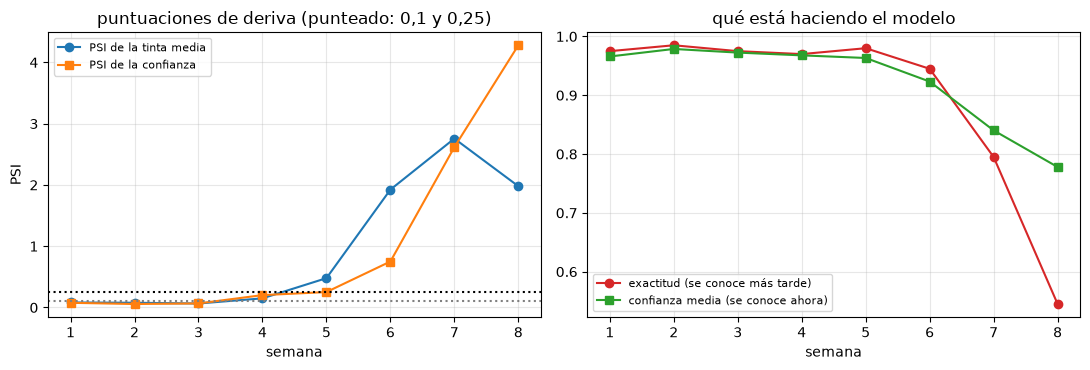


falsas alarmas en 150 lotes de 200 SIN deriva: {'KS p<0.05 on ink': '3%', 'PSI ink > 0.1': '11%', 'PSI ink > 0.25': '0%', 'any of 64 pixels, KS p<0.05': '35%', 'any of 64 pixels, Bonferroni': '0%'}
tiempo 6 s


In [12]:
t0 = time.time()
def psi(ref, cur, bins=10):
    edges = np.quantile(ref, np.linspace(0, 1, bins + 1)); edges[0], edges[-1] = -np.inf, np.inf
    r = np.clip(np.histogram(ref, edges)[0] / len(ref), 1e-4, None); c = np.clip(np.histogram(cur, edges)[0] / len(cur), 1e-4, None)
    return float(np.sum((c - r) * np.log(c / r)))

# ---- comprobaciones de esquema ----
COLS = [f"p{i}" for i in range(64)]
def validate(df):
    problems = []
    missing = [c for c in COLS if c not in df.columns]; extra = [c for c in df.columns if c not in COLS]
    if missing: problems.append(f"missing columns {missing[:3]}")
    if extra: problems.append(f"unexpected columns {extra[:3]}")
    num = df[[c for c in COLS if c in df.columns]]
    if (nan := num.isna().mean().max()) > 0.01: problems.append(f"null rate {nan:.1%} above 1 %")
    if ((num < 0) | (num > 1)).mean().max() > 0.01: problems.append(f"values outside [0, 1] (max {np.nanmax(num.values):.1f})")
    return problems or ["ok"]
good = pd.DataFrame(X_test[:200], columns=COLS)
bad_null = good.copy(); bad_null.iloc[np.random.default_rng(0).random(good.shape) < 0.05] = np.nan
bad_unit = good * 16
bad_col = good.rename(columns={"p5": "pixel5"})
for name, df in [("clean batch", good), ("5 % nulls", bad_null), ("upstream unit change (0 to 16)", bad_unit), ("renamed column", bad_col)]:
    print(f"comprobación de esquema, {name:32s}: {validate(df)}")

# ---- deriva en un flujo ----
net = mlp(0).fit(X_pool, y_pool)
feat = lambda X: X.mean(1)
conf = lambda X: net.predict_proba(X).max(1)
ref_f, ref_c = feat(X_pool), conf(X_pool)
rs = np.random.default_rng(11); fade = [1, 1, 1, 0.95, 0.9, 0.8, 0.7, 0.6]; jitter = [0, 0, 0, 0.02, 0.05, 0.1, 0.2, 0.3]
rows = []
for w, (g, sd) in enumerate(zip(fade, jitter), 1):
    ii = rs.choice(len(X_test), 200, replace=False); Xw = np.clip(X_test[ii] * g + rs.normal(0, sd, (200, 64)), 0, 1)
    ks_f = stats.ks_2samp(ref_f, feat(Xw)); ks_c = stats.ks_2samp(ref_c, conf(Xw))
    pix = sum(stats.ks_2samp(X_pool[:, j], Xw[:, j]).pvalue < 0.05 / 64 for j in range(64))
    rows.append((w, g, psi(ref_f, feat(Xw)), ks_f.pvalue, psi(ref_c, conf(Xw)), ks_c.pvalue, pix, float(conf(Xw).mean()), net.score(Xw, y_test[ii])))
df = pd.DataFrame(rows, columns=["week", "gain", "PSI ink", "KS p ink", "PSI conf", "KS p conf", "pixels flagged (Bonferroni)", "mean confidence", "accuracy"])
print(df.round(3).to_string(index=False))
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
ax[0].plot(df.week, df["PSI ink"], "C0-o", label="PSI de la tinta media"); ax[0].plot(df.week, df["PSI conf"], "C1-s", label="PSI de la confianza")
ax[0].axhline(0.1, color="gray", ls=":"); ax[0].axhline(0.25, color="k", ls=":"); ax[0].set_xlabel("semana"); ax[0].set_ylabel("PSI"); ax[0].legend(fontsize=8); ax[0].set_title("puntuaciones de deriva (punteado: 0,1 y 0,25)")
ax[1].plot(df.week, df.accuracy, "C3-o", label="exactitud (se conoce más tarde)"); ax[1].plot(df.week, df["mean confidence"], "C2-s", label="confianza media (se conoce ahora)")
ax[1].set_xlabel("semana"); ax[1].legend(fontsize=8); ax[1].set_title("qué está haciendo el modelo")
plt.tight_layout(); plt.show()

# ---- falsas alarmas en lotes sin deriva ----
fa = {"KS p<0.05 on ink": 0, "PSI ink > 0.1": 0, "PSI ink > 0.25": 0, "any of 64 pixels, KS p<0.05": 0, "any of 64 pixels, Bonferroni": 0}
nb = 150
for _ in range(nb):
    Xw = X_test[rs.choice(len(X_test), 200, replace=False)]
    fa["KS p<0.05 on ink"] += stats.ks_2samp(ref_f, feat(Xw)).pvalue < 0.05
    p_ = psi(ref_f, feat(Xw)); fa["PSI ink > 0.1"] += p_ > 0.1; fa["PSI ink > 0.25"] += p_ > 0.25
    pv = np.array([stats.ks_2samp(X_pool[:, j], Xw[:, j]).pvalue for j in range(64)])
    fa["any of 64 pixels, KS p<0.05"] += (pv < 0.05).any(); fa["any of 64 pixels, Bonferroni"] += (pv < 0.05 / 64).any()
print(f"\nfalsas alarmas en {nb} lotes de 200 SIN deriva:", {k: f"{v / nb:.0%}" for k, v in fa.items()})
print(f"tiempo {time.time() - t0:.0f} s")

**Lectura.** Las comprobaciones de esquema detectaron las cuatro averías inyectadas a la vez y con un mensaje legible: el lote con nulos (la mayor tasa de nulos por columna fue del 8,5 % frente al 5 % inyectado, un efecto de muestreo de 200 filas), el cambio de unidades aguas arriba (valores hasta 16) y la columna renombrada (informada a la vez como ausente y como inesperada). En el flujo con deriva, las tres primeras semanas se quedan por debajo del nivel 0,1 de PSI (0,065 a 0,082). **La alarma de entrada salta mucho antes de que se mueva la exactitud**: en la semana 4 el PSI de la tinta media es 0,149 (moderado), la prueba KS tiene p = 0,001 y 56 de los 64 píxeles quedan marcados con la corrección de Bonferroni, mientras la exactitud sigue en 0,970; en la semana 5 el PSI es 0,479, por encima del nivel de alarma 0,25, con exactitud 0,980; la exactitud cae por primera vez en la semana 6 (0,945), luego 0,795 en la semana 7 y 0,545 en la semana 8. La propia **confianza media** del modelo es una señal gratuita del daño: cae de 0,963 a 0,923 en la semana 6, antes del colapso de la exactitud, y lo sigue después (0,778 en la semana 8). El PSI no es un medidor de daño: el PSI de la tinta media *baja* de 2,76 a 1,98 en la semana 8 porque el ruido añadido devuelve la tinta media hacia la referencia, aunque la exactitud sea mucho peor. Las mediciones de falsas alarmas en 150 lotes sin deriva son la parte que se suele omitir: la prueba KS sobre la tinta media dio alarma a su nivel del 5 % un 3 % de las veces, **el umbral habitual de PSI de 0,1 saltó en el 11 % de los lotes limpios** (con 200 ejemplos y 10 cajas el PSI tiene un sesgo positivo), el umbral 0,25 nunca, probar cada uno de los 64 píxeles al 5 % dio alarma en el 35 % de los lotes limpios, y la versión corregida con Bonferroni en el 0 %. Calibra los umbrales de alarma con tus propios lotes sin deriva y con tu propio tamaño de lote. Aquí la deriva se aplicó a todas las imágenes a la vez; la deriva real suele ser parcial y puede perjudicar con poco cambio visible en los estadísticos vigilados, así que conserva también la confianza y la exactitud diferida.

## 13. Documentación y versionado

Un conjunto de datos que nadie puede describir ni reproducir no se puede depurar. Dos hábitos arreglan la mayor parte.

Las **hojas de datos para conjuntos de datos** (Gebru et al., 2021) son un cuestionario que se responde al crear un conjunto, agrupado por ciclo de vida: *motivación* (por qué se creó, quién, quién lo financió), *composición* (cuáles son las instancias, cuántas, hay datos ausentes, hay grupos de personas y cómo están representados, hay algo confidencial), *proceso de recogida* (cómo se adquirió, quién lo etiquetó y cómo, durante cuánto tiempo), *preprocesado y limpieza*, *usos* (previstos e inadecuados), *distribución* (licencia, acceso) y *mantenimiento* (quién lo mantiene, cómo se notifican los errores). Su equivalente para modelos es la **tarjeta de modelo** (Mitchell et al., 2019). Las preguntas que más importan para los temas de este cuaderno: quién etiquetó y con qué guías (sección 5), qué duplicados y estructura de grupos existen (sección 6), qué se limpió o reetiquetó y cómo (sección 3) y qué umbrales de monitorización se fijaron (sección 12).

**Versionado.** Los datos cambian más a menudo que el código y rompen los resultados de forma más silenciosa. Práctica mínima viable: dar a cada versión del conjunto un **hash del contenido** (para que "los datos con los que entrenamos" sea un hecho y no un recuerdo), guardar a su lado la versión de la guía de etiquetado y los pasos de limpieza, y registrar el hash en la ejecución de entrenamiento. Herramientas que lo hacen a escala: [DVC](https://dvc.org) (control de versiones de datos, seguimiento de archivos grandes al estilo git), el versionado de conjuntos de datos del Hugging Face Hub y los formatos de tabla de los lagos de datos con viaje en el tiempo. Abajo, una hoja de datos como diccionario simple y los hashes antes y después de la limpieza de la sección 3: el hash cambia, la hoja de datos registra por qué.

In [13]:
def data_hash(X, y):
    h = hashlib.sha256(); h.update(np.ascontiguousarray(X, dtype=np.float32).tobytes()); h.update(np.ascontiguousarray(y, dtype=np.int16).tobytes())
    return h.hexdigest()[:16]

yn_demo = flip_sym(ytr, 0.2, 400); keep = ~cl_flag(oof(lambda: mlp(0), Xtr, yn_demo, 0), yn_demo)
datasheet = {
    "name": "digits-1000-noisy (teaching subset)",
    "motivation": "teach label-noise handling; derived from the UCI optical digits test set (CC BY 4.0, doi:10.24432/C50P49)",
    "composition": {"instances": int(len(ytr)), "features": "64 pixel intensities scaled to [0, 1]", "classes": 10, "missing": "none"},
    "collection": "20 % symmetric label noise injected with seed 400; true labels kept separately for evaluation only",
    "known_issues": ["labels were corrupted on purpose", "no writer identifiers, so duplicates by writer cannot be ruled out"],
    "cleaning": {"method": "confident learning, 5-fold MLP, drop flagged", "examples_removed": int((~keep).sum())},
    "intended_use": "teaching and benchmarking of data-quality methods",
    "inappropriate_use": "any claim about real handwriting recognition",
    "monitoring": "PSI on mean ink, alarm above 0.25; KS with Bonferroni on pixels",
    "maintainer": "course authors; report errors through the course site",
}
datasheet["version_hash_raw"] = data_hash(Xtr, yn_demo)
datasheet["version_hash_cleaned"] = data_hash(Xtr[keep], yn_demo[keep])
print(json.dumps(datasheet, indent=2))
print("el hash es estable entre ejecuciones:", data_hash(Xtr, yn_demo) == datasheet["version_hash_raw"])

{
  "name": "digits-1000-noisy (teaching subset)",
  "motivation": "teach label-noise handling; derived from the UCI optical digits test set (CC BY 4.0, doi:10.24432/C50P49)",
  "composition": {
    "instances": 1000,
    "features": "64 pixel intensities scaled to [0, 1]",
    "classes": 10,
    "missing": "none"
  },
  "collection": "20 % symmetric label noise injected with seed 400; true labels kept separately for evaluation only",
  "known_issues": [
    "labels were corrupted on purpose",
    "no writer identifiers, so duplicates by writer cannot be ruled out"
  ],
  "cleaning": {
    "method": "confident learning, 5-fold MLP, drop flagged",
    "examples_removed": 172
  },
  "intended_use": "teaching and benchmarking of data-quality methods",
  "inappropriate_use": "any claim about real handwriting recognition",
  "monitoring": "PSI on mean ink, alarm above 0.25; KS with Bonferroni on pixels",
  "maintainer": "course authors; report errors through the course site",
  "version_has

## 14. Una lista de comprobación para el trabajo centrado en los datos

1. **Mira primero los datos.** Muestrea 50 ejemplos por clase y léelos; calcula los recuentos de clases y de duplicados antes de modelar nada.
2. **Fija la evaluación antes que el modelo.** Un conjunto de prueba limpio, representativo, **partido por grupos** y que nunca cambia va primero (sección 6); sus etiquetas merecen el mayor escrutinio, porque cada decisión posterior se juzga con él.
3. **Mide la calidad de las etiquetas**, no la supongas: haz etiquetar dos veces un subconjunto y calcula el kappa (sección 5); mira las confusiones, no solo el total.
4. **Ejecuta un detector de ruido** (sección 3) y lee *a mano* los primeros ejemplos marcados antes de eliminar o reetiquetar nada; comprueba con un conjunto reservado que limpiar ayudó, y comprueba con ruido cero que no perjudicó (sección 4).
5. **Dibuja la curva de aprendizaje con banda** (sección 7) antes de comprar etiquetas; si la curva es plana, cambia el modelo o el *tipo* de datos, no la cantidad.
6. **Si las etiquetas son el cuello de botella**: aprendizaje activo con una estrategia híbrida (sección 9), supervisión débil para el grueso (sección 11), y aun así un pequeño conjunto de referencia para evaluar ambos.
7. **Aumenta con conocimiento del dominio**, prueba los aumentos uno a uno; trata los datos sintéticos como un complemento para la cobertura, nunca como sustituto de datos reales nuevos (sección 10).
8. **Valida cada lote** y **monitoriza la deriva** de entradas y salidas, con umbrales fijados a partir de las tasas de falsa alarma sin deriva, no solo de una regla práctica (sección 12).
9. **Documenta y versiona** los datos: hoja de datos, versión de la guía, hash del contenido registrado en cada ejecución de entrenamiento (sección 13).
10. **Decide con números**: cuando existen palancas centradas en el modelo y en los datos, ejecuta el pequeño concurso de la sección 4 en tu propia tarea, con semillas.

## Ideas clave

* La tesis centrada en los datos fue **puesta a prueba, no supuesta**: con ruido en las etiquetas, limpiar los datos con un modelo fijo se comparó con un modelo mayor, ajustado o distinto (sección 4). Con un 20 y un 40 % de ruido en las etiquetas, limpiar con el voto del conjunto subió la exactitud de 0,911 y 0,824 a 0,961 y 0,947, una red mayor la bajó a 0,843 y 0,655, y cambiar a un bosque aleatorio (0,959 y 0,927) capturó la mayor parte de la ganancia sin trabajo alguno con los datos; con etiquetas limpias limpiar perjudicó ligeramente (0,977 bajó a 0,975 y 0,968). Veredicto: cierto con etiquetas ruidosas, no respaldado con etiquetas limpias, y no excluyente de un cambio de modelo.
* El **ruido en las etiquetas** cuesta exactitud de una manera que depende de su estructura: los errores dependientes de la clase fueron más dañinos que los aleatorios con la misma tasa, y las etiquetas de prueba ruidosas también corrompen la *medición* (sección 2).
* **Detectar etiquetas erróneas** funciona sin etiquetas extra, a partir de predicciones fuera de muestra; el aprendizaje confiado, una regla de pérdida y el desacuerdo del conjunto de modelos se compararon con la verdad conocida (sección 3). La calidad de la detección y la ganancia posterior son cosas distintas.
* La **calidad de la anotación** es medible (kappa), se concentra en las clases parecidas y los cambios de guía se pueden probar (sección 5).
* La **fuga** infla la puntuación de prueba sin ningún error en el modelo; las particiones por grupos y la detección de duplicados eliminan la inflación, y una variable que filtra es invisible hasta el despliegue (sección 6).
* Las **curvas de aprendizaje con bandas** dicen si más datos del mismo tipo pueden ayudar; la extrapolación con ley de potencias solo es útil si pasa una comprobación con datos reservados (sección 7).
* La **valoración de datos** ordena los puntos por su contribución; la estimación de Shapley es más ruidosa y cara que dejar uno fuera y medimos ambas (sección 8).
* El **aprendizaje activo** puede ahorrar etiquetas pero las ganancias dependen de la estrategia, de la etapa del presupuesto y de la semilla (sección 9).
* El **aumento de datos** ayuda solo cuando conserva la etiqueta; los **datos sintéticos** no pueden añadir lo que el generador nunca vio; el **entrenamiento recursivo con datos generados** estrecha la distribución y pierde los modos raros salvo que sigan entrando datos reales (sección 10).
* La **supervisión débil** cambia calidad de etiqueta por volumen y se apoya en un supuesto de independencia que vimos romperse (sección 11).
* **Monitoriza** con comprobaciones de esquema y estadísticos de deriva, y calibra las alarmas con lotes sin deriva (sección 12).
* **Documenta y versiona** los datos como el código (sección 13).

## Ejercicios

1. En la sección 2, añade un tercer tipo de ruido: **ruido asimétrico de clase rara**, donde solo la clase 9 se corrompe (a 4) con probabilidad $\rho$. ¿Cómo se compara la exactitud global con el mismo ruido total repartido por igual, y qué muestra la exhaustividad por clase?
2. En la sección 3, cambia la validación cruzada a 2 pliegues y a 10. ¿Cómo se mueven la precisión, la exhaustividad y la exactitud posterior? Sustituye el perceptrón multicapa por el bosque aleatorio como modelo del detector.
3. En la sección 4, añade un brazo de **suavizado de etiquetas** o de **parada temprana** (una defensa centrada en el modelo contra el ruido). ¿Cierra la diferencia con limpiar con un 40 % de ruido?
4. En la sección 5, da a los tres anotadores errores **correlacionados** (todos confunden los mismos pares en el mismo sentido) y compara el voto por mayoría con el caso independiente.
5. En la sección 6, cambia el nivel de ruido de los duplicados de 0,08 a 0,3. ¿A partir de qué nivel el umbral de distancia deja de separar copias de imágenes distintas, y qué pasa con los grupos descubiertos?
6. En la sección 7, dibuja curvas de aprendizaje para el bosque aleatorio y para el perceptrón multicapa con una penalización L2 mayor. ¿Para qué modelo es mejor la extrapolación a 1000? ¿Qué harías con una curva cuyo error de prueba es plano desde $n = 250$?
7. En la sección 8, cambia la utilidad a la pérdida logarítmica en el conjunto de validación en lugar de la exactitud. ¿Es más fiable el orden de los puntos cambiados? ¿Cómo cambia el acuerdo entre mitades independientes de las permutaciones con 60 permutaciones en total y con 960?
8. En la sección 9, añade la **reducción esperada del error mediante un sustituto barato**: consulta por comité con 5 regresiones logísticas bootstrap. ¿Supera a la estrategia híbrida con 100 etiquetas, con 10 semillas?
9. En la sección 10, ejecuta el juguete del colapso con $N = 200$ en lugar de 60. ¿Cómo depende de $N$ la generación en la que desaparece el pico raro? ¿Qué tamaño de muestra hace segura `replace` durante 25 generaciones?
10. En la sección 11, añade una función de etiquetado deliberadamente **mala** (acierto del 50 %) y mira lo bien que el modelo de etiquetas le da menos peso comparado con el voto por mayoría.
11. En la sección 12, añade un **sensor atascado** (un píxel fijo a 0) en la semana 6 y compara qué estadístico lo nota primero: el PSI de la tinta media, el KS con Bonferroni sobre los píxeles o la exactitud.
12. Toma un conjunto de datos de tu propio trabajo, escribe su hoja de datos (sección 13) y responde con honestidad a la pregunta "¿quién etiquetó esto y cómo sabemos que estaban de acuerdo?".

## Referencias

* Ng, A. (2021). A chat with Andrew on MLOps: from model-centric to data-centric AI (charla, DeepLearning.AI): https://www.youtube.com/watch?v=06-AZXmwHjo . Curso: Introduction to Data-Centric AI, MIT (IAP 2024): https://dcai.csail.mit.edu/
* Northcutt, C. G., Jiang, L. and Chuang, I. L. (2021). Confident learning: estimating uncertainty in dataset labels. *Journal of Artificial Intelligence Research* 70. arXiv:1911.00068: https://arxiv.org/abs/1911.00068
* Northcutt, C. G., Athalye, A. and Mueller, J. (2021). Pervasive label errors in test sets destabilize machine learning benchmarks. NeurIPS Datasets and Benchmarks. arXiv:2103.14749: https://arxiv.org/abs/2103.14749
* cleanlab, biblioteca de código abierto para encontrar problemas de etiquetas: https://github.com/cleanlab/cleanlab
* Settles, B. (2009). Active learning literature survey. Computer Sciences Technical Report 1648, University of Wisconsin-Madison: https://minds.wisconsin.edu/handle/1793/60660
* Ratner, A., Bach, S. H., Ehrenberg, H., Fries, J., Wu, S. and Re, C. (2017). Snorkel: rapid training data creation with weak supervision. *VLDB* 11(3). arXiv:1711.10160: https://arxiv.org/abs/1711.10160
* Ghorbani, A. and Zou, J. (2019). Data Shapley: equitable valuation of data for machine learning. ICML. arXiv:1904.02868: https://arxiv.org/abs/1904.02868
* Shumailov, I., Shumaylov, Z., Zhao, Y., Gal, Y., Papernot, N. and Anderson, R. (2023). The curse of recursion: training on generated data makes models forget. arXiv:2305.17493: https://arxiv.org/abs/2305.17493
* Shumailov, I., Shumaylov, Z., Zhao, Y., Papernot, N., Anderson, R. and Gal, Y. (2024). AI models collapse when trained on recursively generated data. *Nature* 631, 755-759: https://doi.org/10.1038/s41586-024-07566-y
* Gerstgrasser, M. et al. (2024). Is model collapse inevitable? Breaking the curse of recursion by accumulating real and synthetic data. arXiv:2404.01413: https://arxiv.org/abs/2404.01413
* Sambasivan, N., Kapania, S., Highfill, H., Akrong, D., Paritosh, P. and Aroyo, L. (2021). "Everyone wants to do the model work, not the data work": data cascades in high-stakes AI. CHI. https://doi.org/10.1145/3411764.3445518
* Gebru, T. et al. (2021). Datasheets for datasets. *Communications of the ACM* 64(12). arXiv:1803.09010: https://arxiv.org/abs/1803.09010
* Mitchell, M. et al. (2019). Model cards for model reporting. FAT*. arXiv:1810.03993: https://arxiv.org/abs/1810.03993
* Cohen, J. (1960). A coefficient of agreement for nominal scales. *Educational and Psychological Measurement* 20(1), 37-46: https://doi.org/10.1177/001316446002000104
* Alpaydin, E. and Kaynak, C. (1998). Optical Recognition of Handwritten Digits (UCI Machine Learning Repository, CC BY 4.0): https://doi.org/10.24432/C50P49
* Great Expectations (validación de datos): https://greatexpectations.io . DVC (control de versiones de datos): https://dvc.org

In [14]:
print(f"tiempo total de ejecución del cuaderno: {time.time() - T_START:.0f} s")

tiempo total de ejecución del cuaderno: 162 s
